# Lab 5 | DC Motor Response Analysis

This notebook uses the recorded M3 and M4 encoder measurements to compare motor behavior in simulation and on the physical robot.

## Experimental data
Each measurement contains three values: **encoder angle (degrees), elapsed time (milliseconds), and PWM command (%)**. Nine supplied recordings are included directly in the notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize
from IPython.display import display
import base64,zlib,io
DATA = {'charos_1at_M3_real(4).txt': '...', 'charos_1at_M3_sim(4).txt': '...', 'charos_1at_M4_real(3).txt': '...', 'charos_1at_M4_sim(3).txt': '...', 'charos_1at_b_M3_real(3).txt': 'eJxNXFuWJSEI+5+13D6nfKHuf2OTQFC/2vStshRRIYLWav+V7/f9M5bqzlI/JTul3bJUSj/FNk5x3OK8xX2KtZwaap2nOO5/5y3uksVW6im280C7r7X7WruN7OXU0PvpYr8t69uyOMottvPaGOfDY97/3pbZd8VU1yn28wmzU6+t0+P53eJ9bfb7Xzs1zHVqWN8t1tPN1c9YLLvFdYr7O8/uejq0++nFHneI5y3uUyxf/W65P+WxbvlKqHz7fKeU8pTbfb6MecvzKe9bruUpt/vdetWzVHvKV9dKu8pWHrUpj96UNh893rf8qE7p1W75jmzp9pTXbcO406k8uoTJ8ZQfWY3nXbtDVeyOVbH+/N+e/6/7LXvkNh+5zUduczzl+ZT3La+rnGXVK5NHz8qjaOXRtLK/27Z9p1TZ7V0Onv/Pp3zbX79abrk/5dv3+q2nfHW1PmtTfRanWuzWU9Yt19vmWuuzQPWn/Hy3Pu+25932tLndOVLbnSO13f7Wdlef2stTvrpae7/vdnvKdwmq487NOvptz7hjVMe6dT46Vq1cudkjKxtPeT7l/SzV5V22b3vmHd86523PvGsCRPiUn/6uO0fquvO6rrt21v095Ts3637G61nR6p5Xbs+a1j581xwMAKz0ASYAZkaADYDp6QCPt1L0C8YX64ve6dyiMFIOBn+xKWAAqwfAeDRocwB8otWaAN+BDgRYBFhbHOwFsKKhHR1vaHYAaExDDQHYBbbJQSMwAbatLYHBX3a0rWNnar0IYP1tvQmgwa0PvbMJJJDxoYIugQy8i94KUFSj6TGMRBsjOse/bUwB4ztQfAfsthUBaHQztcAgpWYjJGoFH7WpXzDgzXZIByLF1l9CIGg27YAQImoA0JgarIM2px5bqG1uAciiLVUwMbZttWjoxGRua+gXDv2aUdtk59aOnk5KdH/R0IkJ2nYNgUzIHDuKAL4Hucc7i0LcqmBBiP2TVi3YAv2rUdvCcPavR7fZkv5Z1MbFt39Lj0EwvXwhxIWh6UUVbHynF3VhFwK1YFe+o2Hc/E7VMG6IrFd1YRs+WtWCPQksvrMhxF6l1xs62lvo9WRXelhGAFDPztnhAJLtzWoA7KMdkg+AWQIDTQCd7GhPACzxvXeBTTsu9HpyImJxnAHwOPS1BcBg9VEF+B0uig5gcPRh+mXylx0fxb7169LEySnaLWbjpAHSTa2mYLrFZJoVtWJeCAwallXvQA/67KoNj/epj9Km7VPd5kzuSxXQWOmrrABQ8r7aDgCTqa8RPeXqgl5H1RQmJqMAx2eXkHVbNG5jfZvcZ/oe8VHoDUCo8uwcn60KMFC/8cVcmJz9IzbeSZGP2Hgn96ARG++kIQ1b5/My+jSKb2Io45nSupc3TWu3omF6oJ7iljrKE2U3Oiae/Y3qBhfKG+UW/6/8v2+AKKNO7ERexrI7qhsdKBvs9S/K0JPRqsq043t8Cxo8mm9KmK58ZqqM+tuOOvHziE0YZXwLmupl9r2r/RjEEYbe5N4Key7ajEkBR2HeshuJk2vdGGa3vPR/1G/fU67tlnu9ZXv+v24Zk+yW61PuT3msW55Ped/vLvXXy23e8vPuet5de5/yLvf/YdypPJ7yvG3e+5TtK08Z/f0zSc4+iFuIioylTYiTZCfCWBl1TQi/0cwLBNFjv8jfuHIUbD2BOB9glQphy7Ra8uvcB2HBCXFBp1fqCDMEaB6EOutOxLncspbOXQ47tBD7gN1SiNths0RQTez0idgyzsxA7kFW9YFKaVwCA3GV7CZJYLMBWnrSd3lMWiGu9Zg+QtxLOSkCcU2niANB1Y0GYiDuHtyhA1EulrKGlfTzTfcvVrZF91aSh9kHlD2qXPCwYgtx8cHiJ8SFDXJMhHbObEvlCjhXIm5rK3tEHgFbpGRdFlHXaHJZwSapOmnpY2NMxE2YuhuIvd1V8iyU9U7p0nPAFijpFsp6pw5+3Cp26uCHaYFpqL5/0F3sb4kGHfzUQS6ieDwRhDCPJn/orX80EMQ1uXn/xa7agEYXwpI7U5ONlgTEUYXQ4ElmJRBmAISaCIWZmuzdxkBlLVA4DIoQ95GZmoxxJGpFCK9AabYQpIu9JxH+PWmzBoJ0obKfkJMaLVHhb11toRWEKaIv0DfwyRQImoxJmAiTBtNVLcM0/vk0D9T5pCXCBMbCl09iaZxjS56TvbUiZOwtJqDQcsYlEXzzadIe6Deki3ETQvPh00hmmPlA2RZWPlOTYYDyPWkyJhR6u7IWrKpAmlVG23iulghr3UxNNu5dc6VcsIv94Kknwl45d8332L+d0iWzNWm/BWL/9kqE/sHsSITvLbrbgWC1YMK540g/Ysnh5nK0vnB8eyETFY5URzWrlHCwNssiePDFVeQIYgrBzA3HDjNlFTm++HlVOetYJldtUcb6sGhQeRltrUnS8Hk5kej7aqLDoLSryRGE1GHCxzMQ1JLzXfHJJeebRtgS2QOH84dFpEYZkoh937iarR5EUZ38f7ShGvm26Duc5x/8VXeOK7RkjaYy3hVzCOcc5eg7OaslsodW9RJ5CCcf5apyJYmnMuo3t3mMa+YSgVgh4iUGsWLbXqIQK5q+ZjjuUY7x8vIKpz/K5T6/2lMeT3ne8v5uPTvIpCjHGEV53vpjr/fyjr1e5R5uGzuwPwsvpWIGYyUygfbb6cxQRrvIRaYgd8kKBn+RL8KtBtZIOGccq01CJ8Ai4SkAwe8qp5aqsau84lb4zpb7DsXarazj/2/a3w7Y6iaflDvobnMcL383+aTwVEmtilpgC7pcSi6Su8sr5ka+exjyRgWEqzjky+OdoW5THfdQCzo/Ooac9MHHsgKsxntkBfyoFVUAZcc6UOW+Q1Qmr3jgiW1yamFbA2wBfnSmYw+Z71nTl0cL6ADHSoWPyrNx+2HPlb483lkaRtJNG3P++PJbng28KtTGpS7WUtTGPTuWWf6SXj6e2LvIsecAb/EM2FIARLyw9fBl4qPYdgHUHNgDP/gpag9nC1AVwmeB1CVsQUQSMbYLIrVpYrRhEoSbii1qEoXHh82MT6Z6klAAkmRW5deTBOJ8I5uu36CPQFXIv5c80JqshYtMbMjOwk85/Zt1ps5yIy9fKi0pfiCRQbvxvWSDoHFE4YAaSTKy+UKTbelZy3IkPmZv1ukGrZstjkK62Br9HOAb8vIppZEEQPff5MnSJgKKKTS5AABNocm2iBmC7vHrVBZzQ4zfkxLDXuIXbMiN99G0me6+v7e7/P3qpxJCxvdgCcv953tcLR0tfl0UEcxO1jJ3MgCshYSlo8onV8xI5wCA1CPuWUDqEbkSoGDb3DwusCH1BdeerR41/95Wj1qhFuwpksBHU2wRLDKej3yfaAKOZhFfNEkvAoWf2zCvAZzhdzagsCkOqDqllHDbPwe+90xygQAjfqn+i1POk5YAQLivPALBK1/8wi6XWsPxh8YD9ADoAIAJLILw2ftiBcGcww1gQ5u8WAqiNLmxH5vTrCRHwMOjQxLAav7Ci6ysrcuFbqygy+/3Vnc50d1/UQXdj5++Qw8AqAWDrabCOmAFNMi+YAV4ZCUX2B9Lf5htsyIHmu9YO14/wAhKwtjqINPncOnYtgumvHFOe7gzL5BPHWBGbdNPzda6YMmtDtCex5YIjADzBft5Z78V7PaCUR4QWiWwL6jftx5QX3Bccnai8qhQsBAep5wCq0W+TEi2lpaQQ1DLOLD6AWE67d3f3ckgcMBrLQkbq6rpm3O/A0znnO4/tXhf/x9wHfj56WP655ttbsdBX6y5yQuAqju0JAi8Cy29a5qUmCHp0nauH7Wnl96bw3TTSc9xOuW7xaGcAcxdwvSSMK/ZqnSTJi0PwJ5evTm0fJgrcR1ZFSlaTNUv33VZWc1fK2u2JGoaDAPOa0FuQoDrS1LAf01vu04KlqeRogX4ITQueQF2YY4kDXzIyFYF5NJe507oY5ReExbpQZhkBMkBwFQz2oOASdqQ+MYql7LyjQGeRP7q390pdt9S4DAk9O/ulbzD5zBb9fG77SsJudS2rx2aoBIeLsAcHjIAdj7gTt4Ab5V2lP/TGXZCjn47yv9RJ1uZ6dlT7O1SAtxNWyq/0SoCPNQCF+2Wyo/dkjWn8hsPMABX/srRb3S1AhZ+t9X06Tn6fvIk2oDSaJZw+rvpBHOfxOr+JeRG0lL5wzJq/VTFGYpZZUkesM19Jvz83X3oAz/X/9LX5+i3kf3lQTdgt+QT2Kqkv8Lma5c14K7RLN3jyTnYLBs5vft2XH7vvh2ff7HNlv216REGWRXpXMB0tWmHA7bkGaiE8FDVfdrGgCshjZ7GwwKRC3x35SjwGAMw6Qza4oAj2Qbv/poJOffbktb5WV1p+5ARjVXtw0ZQ+eHaZM0u9uTE4Fz4uzsh1hPMpayKh4bcpRNS6/rnu6lxiwaIYBM6SADBCnAnZ/hFUBBU+h5nCRAQ60tSYTvQcbp/OGkFKl2vOlCnzHsSC+x5r4rp4XbRk1qgF9BrBoAQtCeCorcmpoHvZPwI7bTedMBNwXTFHmF1YKRIhJCwUoCIdvLVsfcu4L/EqT4tewBVwD2kjyKage+MCCjguTCACVA6OtqvNOa7feGSe0+tCniwSh9JSABEVBLdYYAIMCI9UTBmAmzOjGiI6qKawQrRvAOw8oA1LljfC7ICB/0F9oKI5Aiwv+8B9QVtPmC8ILsAgN16PKC+oL9Ah6He1fHpPNZFMoq8TVI5xc+yHHHhGFTAQKylyAP3IRtFZ+ukFmhSJuKTNWuhQowqHoBMBJDccFIRQDtjET6PIMowhU2UQQvNkU53yc0C6Yi7DUc7ww7Yv15UJzdkzPmMNfDf4mwQE4y97RltUBztLVbCPIJJTETzeCbRCu4RjCFegUs2kHrU/etDPXI/AFaIQgv866bjareyhvUMLqhEiqMYHidlOvImPwFLXKfuw0dstiQlKM8pnsetzTEzeoG7ExxOfYGO0GCwU6yojsQKkMoFipNrrNv8wjIhbpdjyZ+nHwpHQIyT+de3QhrMv861NDYHfn2PJChY505uwXu7JetJWdsnbmFyX7RPrAB7BiRWgOwLkPx5+q9AWQu1zkpVoMJ2JH9+0YazIp6DZyr0X8QtcAO0sjMKYTISTeNOsqY4f+fI/LeRfAXbWTPIgVuSU61uNVCzoN0KGKB0rWk+bO440FkhbgzWFC5CvwNI2rO9t/3LgATWyYU1DCC2pevQ3a0jj3A5ppNlsADlCp/sUyACbV0bOrl3vsIuX+G/DdXC+W4KZPEDICAxDc5XYPDFQnBO++GAI7qu0BOhiOAL8tMPo4pJr/2gqpiINz/EKn5qFsh/U/8K1xc3ZBzRh/ZDE0vD2BkpR1xDMMLBc1Tv7epC3Z80oUEJ0oJzxI3GpNdhxmPcxGVwF7PdFJLgvd0ZoFAiElGImzmcgX7Zi6lgl0mPCahmYIMj9Y/+UnGpumfjAY3JWPC5EhECvkRBbDMYCwciHJqDFYCj6mEd7oFVguALeP4EoDgH2iuzWjmMBXoaJAWVyzv6RUgDQP0OY+EhGp8Yi5mRBhz2maEGZCxmk7vvAZdx6DAZNwWg6AFvdVfIAw3CGebBdCttdgU9cMeaIwgU94LnUHNcioe+8MeSffDHxD6Yh4Ju/cLHrIgv4EctfX9Kx/qlIqYpnIFzb4bhADA9mDQ+6nKLcMBJtgRA5AF1ds75AtEXDpb6E6C+oL/AXjDfCiReB1v9CdCed3YQXAJvc5LLIFhfeUFdD+j9AeliuhTWd+gHen6r5Ak4oxsA6wlh2IT9wEI4D3XBqNqSZ+m+3a2a9INrzKpJP3DpYphuBkB8/utlMtiMmgfqzratdugHTrPV0g926mK1Qz+Yw3T0GTwIOE8EAxvZ9hPCUFYvJ4aBH+pybvxEGPBEHNBAXofJaJxe6zIZk/0dh35w0Y08o2/DHx4jqQu2auRZv1MX64YvuHAs6QenLpYd+oHeG5a/E8/Ami3DRZyxXbYTcs6smYf1bkevmREj3BIBM3SAyQ2AGTtQuU6tmY4+2X+MbjlxDRTOZTI4g9ZlMrz7qDqpC4f7UBeseWcASvHu73aiG9h9bqKiLljzTu6NDhegOIOgLvaXVZGiA8wO0m8DHKqZBUBLJoPd91M8URfG8O8vYfFo8Dyp5nYAKFlh5+aHyjpcBauq6ekyIBGw5sPdYbryDGQEtPyVBz2bZ7oBP488T+rCTZKdvJ3HhwBmVW7MwFYbyVWwquTtjKZg2T1deYYsA9aE3GR37xkuwX1g9xOVQIpo96zKyYk9DsHAjX2P7CBVCLAfcmJ4wHw+3Dx+/kY4EFrKyq3I/cQ4sGY7BAPtz22HYOBk33YIBu6Eex6CgabInkkwmI/vPPES1WEGp5iLfc4T+cCa5yEYXOyrJKR679US0s7YK5WBMXmASfMMH+6VMSpOTuydoS6+q+6dUSq+/e7Udg9cZk5BTXKCVaW2+4kplCyrotMCmGEz9GgAT1X4BGBwBb06iDgEOvn1K+Hqk6AAUA7VYhWZEYWVAEBkgzlQBP+Ynu1wOAmAVpOTABBb4S2ombHRCJQ2Utjypph4zHAApVZ9fKf1lTQEgKIJlj+mcAIIBraRiANvaJfTPFmBUl5INgBEvkn1Vg/FBQxWPUpPSgGgHeIAQGECna0eihPorHrcgIb6WUY0mKd5KLSA7yR14TKwyGrgORyAiIPKCuYnwApmfUEXYEOnvUD9CaC4jkguCf5HIFJQBMb72HzBW8EuL1BYSYDxAglEWSz9AJ4nP0CxJQHGC+T9VQxa5cGh0GQmTDIQ2BF4rJLxF54lI4/LpV+K/HUGo9RSdgZa8L0qBoKmceVxhRgP/y1ZlOUoWZTFrzf5+Qy+qaXJz+d6DJTpEoWtbpYBF45WRlxA5Ur/FFhBlSmKDMe88d90ys2zz1rk7xnjMir5JnEc/N7IvIvN3o6qUAkYBLWMnpEX7MOwG4cBlGyIS2lk7oTLxRTUwO8CZS3TkdXDcVQ6YIfjqGXq9J8cB8+v2uE4gDK4gtOgnOgKTqSiwHGj9ViLPDwPw6i0D8VxsM6MsKCJX8sJsfhYy1LYC1vP4zLFVXBylS3OgWFuQOIceIBZue2I4/DfZuZWsM69MwbjYz6V5MIJCSTOgaZTrSe2ghOzfsrq4M5Sa+ou8yBrzVQbHg9VqpY4jkGULMpypDgcHhUBKbcDxjfzucQ5LGV3KUKD0q11CGGzAxKTxygMIOWo8AgJrxU9uVhLcnDcl1il2AlKt7aTYsGvt+Q/uI7VLlaRIZrMLssoDL6XHBzNn+qpXo6m/yYd5CEPGq08h4/Le81EB8aiAiX/Qd2tI/kP7+1YmXrhv+2MwmAtVjIKg+00RTcwzr96Kpij7b8pLgFrENHObAy2c8qz51gBJXPRWcvsQsPR1JPGWmamcXhvxch5TAZQzaQMylOM3Kw+tiuzKrgf1qW0Ct9A6mEufGx3FfLe7p6sBt/bmdzhY7uTRdls54510B0H5vqJueDYtk9SojYAjYzJ8CcjVIJELHQn4gyoGQARZ9Ao2laCeOCxAYAyLD4HEajAODKAiDNww6NFRqxH1QJE5D39LICh+IxFMBWSwceUIEGtAqjxGCdSa10hGay62ZdsB0BEOnRvm7IkSAZj81CgAjWgdVEFHJDWxTXQJGldXIO3uif1wV8iZtIdWQBV4FIcogqaP2Y7eRDmUO7kQTDA8s07HzNli7jgbbQkRQAU6cDlq9muyZBgkqoCWn1tqgLOwzb74U6YrKnkEFY91wMiRzZBfUH/HmAvUOyIg63gkwDVHtCf2raNB6xbQf8+e8DTgv719xfrDzgRDQ7LoRTY9V5qcgiUUS/9ybBggmqSFd0fzogGmugwCZJS8KHrNSkFH+NeT5KH567WdJOpCIDrSbvAsphhCNQZwEwbYLwZYOYNMGMR0A5kI9vKKAxOdM8pE3fBRvakFMgOAp4Ej8i0zWN5n3S9J4fASrg8nywL9mgks0E+BDBDGGjIACZJ4qtBtwxCwaQibCewgs2wkYEVNAe6zUNWsEd2SAP/7uUfvPszowN4GAWYnj7P/wDT0yc7BHiSMzjX+jrZGZyhcI8S+iislDMPAgBz9H1V7hmRHkt2v4EV5rnJ9cRZsAs7uSnGhgNmxggJAcAcMvLk2Ny+k33xEdYTWDEJM2CHMRSA2SpqOeBKyOEel3/oDlO9mYMB2E9gBWsuyU19H6sqh0PADs4M64Q0c0etCenKjSTfjIY9YIYD7O4wo/fdCBip3h5YAZguNoM4AQ+HQOUfLfMjSHQC7gyO4L45aE+IrGAHeSgnOoId7CdDo/DdLuF46AS2ii8JBy7w4/IP3sHRE1Kfx7DDTrDmsZ7QCajaSdTg3B+WPZpU73GSLGZxmKQBjWDAQxrQchzJtsGsZM0zSQPSzoDZQTdIxxwnKYPdn+npuyk7Znr6bueOVU7ohHk6fJIG3v0bK8GNcNxYCfN3M8zE94uxU+z0GwBr5mr4+O6RQRmVrdo5Cr5Djr1O6MRiJv53Qic8MT8jVjoaAJijQOIUMAklxg8ALgVPGNP4w3nmKS1A5EL4OmYl/H9fxawopZ7GjZWlVA2CqlwK/3DezUJL36quIKDMLe/aYM+dRvgiML5aJmNQ+PZehWCZjsF5Zk0XKVAa1nQrAVXBkoHYfKwrcICzz7oCB2jsW1fgwPJflOFAW8aGUhzIWpguRSA1CJDBE/zOUOgCVdlG8hmUmynywHtqSpIYrM0y8oDvmNIkfBRMeRIukIjnDKbDdAUH977qDs4XyQ7V5njBnA+Q/097zkOeLpD/H0CJKQHmC94K9lvBbi9QdkoABYMEWBd4RtoF9QXje8B8wb55HdUXdUuROD1tKTpMbj1JEUcGXw6FH2k64j7uIdiBFpEcJ5q4QHLieElCdZPeUnHmoSNot86kI5wkm61l9gfb0jIxhBNoHjqCdoIfTzgiNTIPHUEjyQ8dHZkjUQA+pfwI0RGX8pkERPevj5qZH2zZJSAcJXXgEpTbZm7CTPsyrIK9tbz+gfo/rSflwO+ZQgTcivJ0Nl+F6KROk6M9/OuzZFgFZTblrrulPefIIAv/TY42W8g4TdU5KZeV+SL+9VWTgGBv10jKgbUsucjml4KsvIqBttFUAruRTAHKPI/hv3UFUnBRnluhIcwBYZCofuNyvk6qB7e6dVI9ONIrk5CcgFifEiPYa3qe6xIQ6xMF4JveKmoZjSqgvCZi+WUmIwkI1lkUvLA40uvSEURVFIBv0aueqx7Y6joyKYS1pCYv8/d2poF8vDAla+E6vloSCVxGVxJrlCTDYxUe4b1tcbgPIfHrqclkzIEkJca90s8W4hxb/Vz74L8lHeG97UkkeG9HEgk0btZIIoHzaA17CIh16AjO8GVJatAlX5akBo2+ZUlqcBYvU7gCOXcghSsUbrZryunnOgP03AEBpFskuOoA5TUSPpp5IwOdGmxqX4ZV8L2Vlzpw5qy8lIEnekAjk0L8N92q4OvgWluI89ZP6ByZo/ZdAmLtnmEVrFMZTJ6YC7QyRWTy4ptzWcQmUst8y91fz7CKRqT++a69pdeetAtNioN2posDFGWFDAKlbvjHMpKiOFAkBXmlXT9REA7C9SR/BRCxD50zZkdsZbAOOy7mmk6O7riZy8MZAIIA4NE0gBgEGv+75V0RbFvbyv3gd7qCDbxtGTxBFmh3ec+cX7uLQaD67a5gA47OHspU4Oa8h4IN6K3soYQTTsI9Hp9/mz7KIdymiACu+ztDJLynJtKADuk+GR5858nwABDrwKV7J+sQQCEfLqp5YyzITbUH1BcoJiGAvWA9j23dHBFAMSMBFMISYLxgvmAfAP+0lAe0F4zvAWYPuM1pX8kEenYcMI/AKSHAQxMYr2Eq9zYIXt5U9hNLAacqHWMOHGB6s9xaAfNmAK5IgOtkhRTCU1VcC3Wq4sVDX2sJP4cZecCNlZH+CRd71DJcgJt/+/q5GcK70NuJpXCYnj8NXMCTJMLrhr7x5Z0PUE/AcmIp/LqqdugJtnkkl0Eusfkpm9gKfzfDBRgbDUO9nNAKPmwpK7+66rOMSuEBJOC5bKKyR5Y+dvNmzO+wFfw1D4xndeHMvJ6B3CrzHvJXXn71zQwXgIfFa7aSQuLpPmAmxfC0CjCjUqpLY51rJ3hp07fWCa1gB3dSSAytAMz4j+KDstsTWtH8NE5sBT90Lnworjk7B7T49V9fOaEVlTBFRzu3MUPykhetXHqCV3qVL6NweOrBm8QSshmlJGnC6yMAU3QM/ATMKJyvseaS8S5MPGnMwkryYvCyzMMpUBmYbiTI+7aY2JPkBd9N9s3Ji8ZUliQvut9wlu82h+1khbD7LbMz9seaW+YFMOmxMU9AkFdulV5O4AVb1TMCgEMJmNkoy+9P68kLMKmhMQ48qQ02cpxrKlzsoyV0sedc8BxdwKyK1msrORf8zpFWci54YG1jHOrlMhrDPZPL8Ifn4TL84Z2hFZvdnzfwgr9etoJaVy5b4cN92YrBLly2wod7ZQc5NxtDtJLLYI/WOFyGw3nSQNjIy1YsVrW/JCC4BJXLVvhw734ummAz9qmq+bvJN3HxaQx6EORkZzhCchnTL7Y7XMYgPGwFh5un5oJc+mpyc8YMuFYzw4NzrCZjUf2XiFjgQtpqZKD6pRONB4vJZTSe8yWX0c7FjVzseJoVXIYDXVVJmfME5ye3rvEoJegLI9CNk5xrteVVgqy66Z7S4u/oMkGOQu26SZEqWHsLX5nzr+qeUJ6Jt5qMhTc0Ayi4HuQ1jkwFaHWoAvNfxBdwta5DAQcuxhFXZtIHhucqwmGwgoex4GWCJ1ei5XWOFBKTvhSbQemEfeJ+fKtTEQuNLdCVjtWlM3UVBq8ZrIexoEBWXvbQ/NLC/oAkHBwkX+Bglwt2Eg4O6gv6C94KdgaRNF6O+JUH1Bf0/gAl3QRIyoOguGH4HzOOkvA=', 'charos_1at_b_M3_sim(4).txt': 'eJxd3Vty7DgORdH/HktVBHHAF+Y/sZacBLhVXwaiWzyKWwll2suk2z/e/mn/a//035fx+zJ/X9bvy/59id8Xa+erna86X89Kdpays5adxeysZmc5O+vprKezns56OuvprKezns56OuvprKeznp/1/KznZz0/6/lZz896ftbzs56f9TzyX+Z8Pev1s17Pf7mzXj/r9bNeP+v1s16P/Cc+X89646w3znoj/1Oc9cZZb5z1xllvRP63Ol/PevOsN89686w387/tWW+e9eZZb0b+Rz9fz3rrrLfOeuust856K18sZ7111luRr57z9ay3z3r7rLfPevust896O199Z70d+TI8X896cdaLs16c9eKsF2e9OOtFvpzv6zmLfEW3fEm3fE23fFG3fFW3fFm3fF23fGG3XPmOSq5cw1LTUuNS81IDUxNTI5MzYzk0pprCXDnnxnJwLCfHcnQsZ8dyeCynx3J8LOfHvAY8V84RspwhyyGynCLLMbKcI8tBspwky1GyXs+OXDmnyXKcLOfJcqAsJ8pypCxnynKoLKfKRj2WcuUcLMvJshwty9myHC7L6bIcL8v5shwwm/XEy5VzxiyHzHLKLMfMcs4sB81y0ixHzXLWbNXDNFfOcbOcN8uBs5w4y5GznDnLobOcOsuxs13P6Vw5J89y9Cxnz3L4LKfPcvws589yAC0n0KLeAu57QBb5LpAzqJxB5QwqZ1A5g8oZVM6gcgZl9faSK+cMKmdQOYPKGVTOoHIGlTOoet+qN677zpUr13tXvXnVu1e9fdX7V72B5QwqZ1A5g/J6U8yVcwaVM6icQeUMKmdQOYPKGVTOoHIG1ev9NlfOGVTOoHIGlTOonEHlDCpnUDmDyhnUqLfyXDlnUDmDyhlUzqByBpUzqJxB5QwqZ1CzPiXkyjmDyhlUzqByBpUzqJxB5QwqZ1A5g1r1ASRXzhlUzqByBpUzqJxB5QwqZ1A5g8oZ1K7PNrlyzqByBpUzqJxB5QwqZ1A5g8oZVM6goj423c9NWeQnp5xBf2dw/qr+V/lTjarmXxVPtaraf5XNp4wq32F8Sj0XveOYpX7lc5n5LU/Se9m45S+r6ynXLX9p/b0sqtQvbTyXyW75S5vPZfJb/tLme9m45S9tjadct/yl7feyqNJ/afu5zO2Wv7R4LnO/5S/t+aDx1AP1PPV+6oX6/Gvae23cuv8ynzf/pzbUOvVzbXfUJ9ffawfqk9vtqRfqk9vfa+PW4+SO59phqE/ufK4dJ3e+//+OeqA+uas/9UJ9cve7Ttx6ntz9XDsN9cmN59rpqH+5z7vKUw/U89TrqRfqX+7zhvDUcet1Xrd6rl2G+rxy9Vy7HPXJ9ffagfrk9vfbjYX65Pb32rj1PrnjuXYb6pM7329XHPXJne+1A/XJXc+07YX65O732rh1nNz9XBuGOif1uTYc9ZnV9l47UM9TP3MXC/Uv9xn3p46qe/vlvkPTm6HWqedTO+qT6++1A/XJ9Xjqhfrk9vfauPV5Lj2v2ac21Cd3PNeeR9OvzmfTe+1AfXKXnnqhPrnrvTZufZ5Qz3+fpzbUJzeea89D6lef3HivHajPU7GNp16oz3PR3mvj1udZ9dzLUxtqnUfqc+15XP3qX+7zvz/1QH1yfT/1Qn1y+3tt3Po8r/p4rj3Pq199csdz7Xle/eqTO99rB+qTu+ypF+qTu95r49bnedX3c+15Xv3qkxvPted59atPbrzXDtS/3NH6Uy/Uv9xh77Vx6/O8GvZce55Xv/qXO/Rce55Xv/qXO/y9dqA+ub6eeqE+uf29Nm59nldjPNee59WvPrnjufY8r371yZ3vtQP1yV3vjzMW6pO73mtP7u7vjzpQG+qTG++PQxz1yY1nnfO8+tW/3NmeGTzPq1/9y33/Kft5Xv3V53k17bn2PK9+db7XP9eGoz7v9v5eO1Cf3OeTRj/Pq199cvt7bVQ9zvPq/U81zvPqV5/c5/PG+H3/8injKfstxy3nLdct9y2jyt83Nr/Sbqlb3jS7aXbT7KbZTbObZjdNN003TTdNN003TTdNN003TTdNN81vmt80v2l+0/ym+U3zm+Y3zW+a37R+0/pN6zet37R+0/pN6zet37R+0/pNGzdt3LRx08ZNGzdt3LRx08ZNGzdt3LR50+ZNmzdt3rR50+ZNmzdt3rR50+ZNWzdt3bR109ZNWzdt3bR109ZNWzdt3bR90/ZN2zdt37R90/ZN2zdt37R90/ZNi5sWNy1uWty0uGlx0+KmxU2LmxaVNlu7pd1St3zS/j3PmPk+TW4z2Mxs3ifSYrNP8zzI5vtcqeZ9svx7Hn3zfbbcRtk8C5izyTvQu8Bgk3fwPJCnLTZ5B++T0wKN8g6eh/6UsTl38L5NTDmbns27wGBz7uB9K5pabM4dvG9kU4HGWzbPAm5s8g6eN8jpzibvYLwLDDZ5B8+b8PTFJu+gvwsEmp538LzRz25s8g6ejwazO5u8A70LDDZ5B8/Hj9kXm7wDexcINCPv4PmIM4exOXfwfiiaw9n0bN4FBptzB+8HrzkWm3MH70e1OQLNbNk8C0xjk3fwfByc09nkHYx3gcEm7+D5yDnnYpN30N8FAs3KO3g+1s5lbPIOng/CczmbvAO9Cww2eQfPh+25Fpu8A3sXCDQ77+D5QD+3sTl38H4LMLez6dm8Cww25w7ebzPmXmzOHbzfmMwdaKJl8ywQxibv4PnmZ4azyTt4n1Ux2OQdPN9gzVhs8g76u0DcZrW8g+ebuNWMTd7B823fymfir8k70LvAYJN3oFe7Fpu8A3sXCDT5THy/fV35TPw1eQftNTNnc+7g/RZ55TPx15w7eL+pXvlM/DU7m3eBQJPPxPcb95XPxF9z7uD9Vn/lM/HX5B3Md4HBJu9g9KdZbPIO+rtA3kH/A0A2xibvwJ8F8pn4a/IO9KyWz8Rfk3cge5rFJu/A3gUCTT4T3x/WrHwm/pq8g/YskM/EX3Pu4P2B0Mpn4q85d/D+CGnlM/HX7GzeBQJNPhPfH1OtfCb+mnMH7w+2Vj4Tf03ewXwXGGzyDsZ4msUm76C/CwSafCa+P6Bb+Uz8NXkH/iyQz8Rfk3egd4HBJu9AeprFJu/A3gUCTT4T3x9Nrnwm/pq8g/YskM/EX3PuIN7rB+qTv59ZzgfiX33S93tt3Dqfhuu5Nh+Gf3V+MnmuzUfhX12fS556oM73w2eC8zH4V+dz+L02bp3PwP5cm4/Av7qegE/tqGv2n3qgzlf9M7f58Pur81/7vTaq3vnki6e0W2bqU/596vwUCerpZDudbKeT7XSynU6208l2OtlOJ9vpZDudbKeT7XSynU6208l2OtlOJ9vpZDudbKeT7XSynU6208l2OtlOJ9vpZDudbKeT7XSynU6208l2OtlOJ9vpZDudbKeT7XSynU6208l2OtlOJ9vpZDudbKeT7XSynU6208l2OtlOJ9vpZDudbKeT7XSynU6208l2OtlOJ9vpZDudbKeT7XSynU6208l2OtlOJ9vpZDudbKeT7XSynU6208l2OtlOJ9vpZDudbNfvhtQvh9Rvh9Svh9Tvh9QviNRviNSviNzfEcmV08l2OtlOJ9vpZDudbKeT7XSynU6208l2OtlOJ4t0skgni3SyKCeLcrIoJ4tysigni+tkcZ0srpPFdbK4ThbXyeI6WVwni+tkcZ0srpPFdbK4ThbXyeI6WVwni+tkcZ0srpPFdbK4ThbXyeI6WVwni+tkcZ0s4GQBJws4WcDJAk4WcLKAkwWcLOBkAScLOFnAyQJOFnCygJMFnCzgZAEnCzhZlJO99XWygJMFnCzgZAEnCzhZwMkCThZwsoCTBZws4GQBJws4WcDJAk4WcLKAkwWcLOBkAScLOFnAyQJOFnCySCd7PrMGnCzgZAEnCzhZwMkCThZwsoCTBZws4GQBJws4WcDJAk4WcLKAkwWcLOBkAScLONn7K2u/Rn+/v2ZsLpU9jbO5WPY0g83lsqdZbC6YPU2gAZk9jbG5aPY0zuay2dMMNhfOnmaxuXT2NIEGePY0xuby2dM4mwtoTzPYXEJ7msXmItrTBBow2tMYmwtpT+NsLqU9zWBzMe1pFpvLaU8TaABqT2NsLqk9jbO5qPY0g81ltadZbC6sPU2gAa09jbG5uPY0zuby2tMc92n9bSabxeYS29MEGiDb0xiby2xP42wutD3NYHOp7WkWm4ttTxNowG1PY2wuuD2Ns7nk9jSDzUW3p1lsLrs9TaABvD2Nsbn09jTO5uLb0ww2l9+eZrG5APc0gQYE9zTG5iLc0ziby3BPM9hciHuaxeZS3NNcizMDxplB48zAcWbX4/5T18/szS7JmV2TM7soZ3ZVzuyynNl1ObMLc2ZX5swuzZkZcg25hlxDriHXkCvkCrlCrpAr5Aq5Qq6QK+QKuY5cR64j15HryHXkOnIduY5cR25HbkduR25HbkduR25HbkduR25H7kDuQO5A7kDuQO5A7kDuQO5A7kDuRO5E7kTuRO5E7kTuRO5E7kTuRO5C7kLuQu5C7kLuQu5C7kLuQu5C7kbuRu5G7kbuRu5G7kbuRu5G7kZuIDeQG8gN5AZyA7mB3EBuIPeCn+mKn+mSn+man+mi318H9TOR/Ux0PxPhz0T5M5H+TLQ/E/HPRP0zkf9M9D8TAdBEATSRAE00QBMR0EQFNJEBTXRAEyHQRAk0kQJNtEATMdBEDTRdDvxtqvh09ukggiaSoIkmaCIKmqiCJrKgiS5oIgyaKIMm0qCJNmgiDpqogybyoIk+aCIQmiiEJhKhiUZoIhKaqIQmMqGJTmgiFJoohSZSoYlWaCIWmqiFJnKhiV5oIhiaKIYmkqGJZmgiGpqohiayoYluaCIcmiiHJtKhiXZoIh6aqIcm8qGJfmgiIJooiCYSoomGaCIimqiIJjKiiY5oIiSaKIkmUqKJlmgiJpqoiSZyoomeaCIomiiKJpKiiaZoIiqaUxXNyYrmdEVzwqI5ZdH80uLf7qn56dangy6akxfN6YvmBEZzCqM5idGcxmhOZDSnMpqTGc3pjOaERnNKozmp0ZzWaE5sNKc2mpMbzemN5gRHc4qj+SXH9bflLLu/DWj26aCO5mRHc7qjOeHRnPJoTno0pz2aEx/NqY/m5Edz+qM5AdKcAmlOgjSnQZoTIc2pkOZkSHM6pDkh0pwSaU6KNKdFmhMjzamR5uRIc3qkOUHSnCJpTpI0p0maEyXNqZLmZElzuqQ5YdKcMmlOmjSnTZoTJ82pk+bkSXP4pDmA0hxCaQ6iNIdRmgMpzaGU5mBKczilOaDSHFJpDqo0h1WaAyvNoZXm4EpzeKU5wNIcYmkOsjSHWZoDLc2hluZgS3O4pTng0vqVS+uXLq1fu7SeZvmpDspYr722vTbb9tpt22u7ba/9tr023Pbacdtry22/O9Rr022vXbe9tt322nfba+Ntr523vbbe9tp722vzba/dt7223/baf9trA26vHbi9tuD22oPbaxNur124vbbh9tqH22sjbq+duL224vbai9trM26/u3Hvdty7H/duyMWO3Mq4e3Lvpty7K/duy619ub025vbamdtra26vvbm9Nuf22p3ba3tur/25vTbo9tqh22uLbq89ur026fbapdtrm26vfbq9Nur22qnba6tur726vTbr9tqt22u7bq/9ur027Pbasdtry26vPbu9Nu322rXba9tur327vTbu9tq522vrbq+9u7027/bavdtr+26v/bu9NvD22sHbawtvrz28vTbx9trF22sbb699vL028vbaTT9qO/2o/fSjNtSPElIbRaQ2ykhtFJLaKCW1cZnUxnVSGxdKbVwptXGp1Ma1UhsXS21cLbVxudTG9VIbF0xtXDG1ccnUxjVTGxdNbVw1tXHZ1MZ1UxsXTm1cObVx6dTGtVMbF09tXD21cfnUxvVTGwBUGxBUGyBUGzBUG0BUG1BUG2BUG3BUG4BUG5BUG6BUG7BUG8BUG9BUG+BUG/BUGwBVGxBVGyBVGzBVG0BVG6mq7welAVa1AVe1AVi1AVm1AVq1AVu1AVy1AV21AV61AV+1AWC1AWG1AWK1AWO1AWS1AWW1AWa1AWe1AWi1AWm1AWq1AWu1AWy1gV2JNsCtNuCtNgCuNiCuNkCuNmCuNoCuNqCuNsCuNuCuNgCvNiCvNkCvNmCvNoCvNqCvNsCvNuCvNgCwNiiwkwI7KbCTAjspsJMCOymwkwI7KbCTAjspsJMCOymwkwI7KbCTAjspsJMCOymwkwI7KbCTAjspsJMCOymwkwI7KbCTAjspsJMCOymwkwI7KbCTAjspsJMCOymwkwI7KbCTAjspsJMCOymwkwI7KbCTAjspsJMCOymwkwI7KbCTAjspsJMCOymwkwI7scPRJgV2UmAnBXZSYCcFdlJgJwV2UmAnBXZSYCcFdlJgJwV2UmAnBXZSYCcFdlJgJwV2UmAnBXZSYCcFdlJgJwV2psC+P3KeFNhJgZ0U2EmBnRTYSYGdFNhJgZ0U2EmBnRTYSYGdFNhJgZ0U2EmBnRTYSYFdFNhFgV0U2AV1/dZXUhYEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZDYDcEdkNg90dg90dg9xXY9nbz061PR4HdH4HdH4HdH4HdH4HdH4HdH4HdH4HdH4HdH4HdH4HdH4HdH4HdH4HdH4HdH4HdH4HdH4HdH4HdH4HdH4Hd3JBp+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw+yOw8RHY+AhsfAQ2PgIbH4ENbu60+AhsfAQ2PgIbH4GNj8DGR2DjI7DxEdj4CGx8BDY+AhsfgY2PwMZHYOMjsPER2PgIbHwENj4CGx+BjY/Axkdg4yOw8RHY+AhslMC+PzyKj8DGR2DjI7DxEdj4CGx8BDY+AhsfgY2PwMZHYOMjsPER2PgIbHwENj4CGx+BjY/Axkdg4yOw8RHY+AhsfAQ2PgIbH4GNj8DGR2DjI7DxEdj4CGx8BDY+AhsfgY2PwMZHYOMjsPER2PgIbHwENj4CGx+BjY/AxkdggwIbFNigwAYFNiiwQYENCmxQYIMCGxTYoMAGBTYosEGBDQpsUGCDAhsU2KDABgU2KLBBgQ0KbFBggwIbEFi1K7BqV2DVrsCqpbt+qqM/avek1XvU6j1r9R62WqettjputdV5q60OXG114mqrI1dbnbna6tDVVqeutjp2td3zwuvg1VYnr7Y6erXV2autDl9tdfpqq+NXW52/2uoA1lYnsLY6grXVGaytDmFtdQprq2NYW53D2uog1lYnsbY6irXVWaytDmNtdRprq+NYW53H2upA1lYnsrY6krXVmaytDmVtdSprq2NZW53L2upg1lYns7Y6mrXV2aytDmdtdTprq+NZW53P2uqA1lYntLY6orXVGa2tDmltdUprq2NaW53T2uqg1lYntbY6qrXVWa2tDmttdVprq+NaW53X2urA1lYntrY6srXVma2tDm1tdWprq2NbW53b2urg1lYnt7Y6urXV2a2tDm9tdXprq+NbW53f2uoA11YnuLY6wrXVGa6tDnFtdYprq2NcW52lXAeaq040Vx1pLiuBlZXAykpgZSWwshJY2RVY2RVY2RVY2RVY2RVY2RVY2RVY2RVY2RVY2RVY2RVY2RVY2RVY2RVY2RVY2RVY2RVY2RVY2RVY2RVY2RVY2RVY2RVY2RVY2RVY2RVYGQRWBoGVQWBlEFgZBFYGgZVBYGUQWBkEVgaBlUFgZRBYGQRWBoGVQWBlEFgZBFYGgZVBYGUQWBkEVoZ9rTIIrAwCK4PAyiCwMgisDAIrg8DKILAyCKwMAiuDwMogsDIIrAwCK4PAyiCwMgisDAIrg8DKILAyCKwMAiuDwMogsDIIrCwFdr7XQGBlEFgZBFYGgZVBYGUQWBkEVgaBlUFgZRBYGQRWBoGVQWBlEFgZBFYGgZVBYGUQWAkCK0FgJQisBIGVILASBFaCwEoQWAkCK0FgJQisBIGVILASBFaCwEoQWAkCK0FgJQisBIGVILASBFaCwEoQWAkCK0FgJQisBIGVILASBFaCwEoQWAkCK0FgJQisBIGVILASBFaCwEoQWAkCK0FgJQisBIGVILASBFaCwEoQWAkCK0FgJQisBIGVILASBFaCwEoQWAkCK6XA2t81m02ggcBKEFgJAitBYCUIrASBlSCwEgRWgsBKEFgJAitBYCUIrASBlSCwEgRWgsBKEFgJAitBYCUIrIQ9sBIEVoLAShBYCQIrQWAlCKwEgZUgsBIEVoLAShBYCQIrQWAlCKwEgZUgsBIEVoLAyiGwcgisHAIrv+r6n7okRX4FVn4FVn4FVn4FVn4FVn4FVn4FVn4FVn4FVm7INeQacg25hlxDrpAr5Aq5Qq6QK+QKuUKukCvkOnIduY5cR64j15HryHXkOnIduR25HbkduR25HbkduR25HbkduR25A7kDuQO5A7kDuQO5A7kDuQO5A7kTuRO5E7kTuRO5E7kTuRO5E7kTuQu5C7kLuQu5C7kLuQu5C7kLuQu5G7kbuRu5G7kbuRu5G7kbuRu5G7mB3EBuIDeQG8gN5AZyA7mB3Cuw6ldg1a/Aql+BVafAqlNg1bkHVp0Cq06BVafAqlNg1Smw6hRYdQqsOgVWnQKrToFVp8CqU2DVKbDqFFh1Cqw6BVadAqtOgVWnwKpTYNUpsOoUWHUKrDoFVp0Cq14C+75hdwqsOgVWnQKrToFVp8CqU2DVKbDqFFh1Cqw6BVadAqtOgVWnwKpTYNUpsOoUWHUKrDoFVp0Cq06BVafAqlNg1Smw6hRYdQqsOgVWnQKrToFVp8CqU2DVKbDqFFh1Cqw6BVadAqtOgVWnwKpTYNUpsOoUWHUKrDoFVp0Cq06BVafAqlNg1Smw6hRYdQqsOgVWnQKrToFVp8CqU2DVKbDqFFh1Cqw6BVadAqtOgVWnwKpTYNUpsOoUWHUKrDoFVp0Cq06B1aDAalBgNSiwGhRYDQqsBgVWgwKrUQJrf9ftTxfsKLAaFFgNCqwGBVaDAqtBgdWgwGpQYDUosBoUWA0KrAYFVoMCq0GB1aDAalBgNSiwGhRYDQqsBgVWgwKrwT2wGhRYDQqsBgVWgwKrQYHVoMBqUGA1KLAaFFgNCqwGBVaDAqtBgdWgwGpQYDUosBoUWA0KrAYFVoMCq0GB1aDAalBgNSiwGhRYDQqsBgVWgwKrQYHVoMBqUGA1KLAaFFgNCqwGBVaDAqtBgdWgwGpQYDUosBoUWA0KrAYEVgMCqwGB1YDAakBgNSCwGhBYDQisBgRWAwKrAYHVgMBqQGA1ILAaEFgNCKwGBFYDAqsBgdWAwGpAYDUgsBoQWA0IrAYEVoMCOyGwEwI7IbCz3JVV6s8sgZ0lsLMEdpbAzhLYWQI7S2BnCewsgZ0lsLMEdpbAzhLYWQI7S2BnCewsgZ0lsLMEdpbAzvvXm0tgZwnsLIGdJbCzBHaWwM4S2FkCO0tgZwnsLIGdJbCzBHaWwM4S2FkCO0tgZwnsLIGdJbCzBHaWwM4S2FkCO0tgZwnsLIGdJbCzBHaWwM4S2FkCO0tg5/0LmfdPZN6/kXn/SOb9K5n3z2Ti72RWxv1LmfdPZZbAzhLYWQI7S2BnCewsgZ0lsLMEdpbAzhLYWQI7S2BnCewsgZ0lsLMEdpbAzhLYWQI7S2BnCewsgZ0lsLMEdpbAzhLYWQI7S2BnCewsgZ0lsKsEdpXArhLYdQV2XYFdV2DXFdh1BXZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdlFgFwV2UWAXBXZRYBcFdlFgFwV2UWAXBXZRYBcFdlFgFwV2UWAXBXZRYBcFdlFgFwV2UWAXBXZRYFcK7P67ZrOBwC4K7KLALgrsosAuCuyiwC4K7KLALgrsosAuCuyiwC4K7KLALgrsosAuCuyiwC4K7KLALgrswh5YLQrsosAuCuyiwC4K7KLALgrsosAuCuyiwC4K7KLALgrsosAuCuyiwC4K7KLAbgrspsBuCuymwG4K7KbAbgrspsBuCuymwG4K7KbAbgrspsBuCuymwG4K7KbAbgrspsBuCuymwG4K7KbAbgrspsBuCuymwG4K7KbAbgrspsBuCuymwG4K7KbAbgrspsBuCuymwG4K7KbAbgrspsBuCuymwG4K7KbAbgrspsBuCuymwG4K7KbAbgrspsBuCuzGHlhtCuymwG4K7KbAbgrspsBuCuymwG4K7KbAbgrspsBuCuymwG4K7KbAbgrspsBuCuymwG4K7KbAbgrspsBuCuwugf27prMZbCCwmwK7KbCbArspsJsCuymwmwK7KbCbArspsJsCuymwmwIbFNigwAYFNqCu3/pKSkBgAwIbENiAwAYENiCwAYENCGxAYAMCGxDYgMAGBDYgsAGBDQhsQGADAhsQ2IDABgQ2ILABgQ0IbEBgAwIbENiAwAYENiCwAYENCGxAYAMCGxDYgMAGBDYgsAGBDQhsQGADAhsQ2IDABgQ2ILABgQ0IbEBgAwIbENiAwAYENiCwAYENCGxAYAMCGxDYgMAGBDYgsAGBDQhsQGADAhsQ2IDABgQ2ILABgQ0IbEBgAwIbENiAwAYENiCwAYENCGxAYAMCGxDYgMAGBDYgsAGBDQhsQGADAhsQ2IDABgQ2ILBxBdbbFVhvV2C9XYH1RoH1RoH1RoH1RoH1VgL7PCi9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9cQ+sNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsGwXWjQLrRoF1o8C6UWDdKLBuFFg37oF1o8C6UWDdKLBuFFg3CqwbBdaNAutGgXWjwLpRYN0osG4UWDcKrBsF1o0C60aBdaPAulFg3SiwbhRYNwqsGwXWjQLrRoF1o8C6lcDq77r+6cang8C6UWDdKLBuFFg3CqwbBdaNAutGgXWjwLpRYN0osG4UWDcKrBsF1o0C60aBdaPAulFg3SiwbhRYNwqsGwXWjQLrRoF1o8C6UWDdKLBuFFg3CqwbBdaNAutGgXWjwLpRYN0osG4UWDcKrBsF1g0C6waBdYPAukFg3SCwbhBYNwisGwTWDQLrBoF1g8C6QWDdILBuEFg3CKwbBNYNAusGgXWDwLpBYN0gsG4QWDcIrBsE1g0C6waBdV2BdV2BdV2BdaW7fqqjP64UWFcKrCsF1pUC60qBdaXAulJgXSmwrhRYl1WGVYZVhlWGVYZVhipDlaHKUGWoMlQZqgxVhipDleGV4ZXhleGV4ZXhleGV4ZXhleGV0SujV0avjF4ZvTJ6ZfTK6JXRK6NXxqiMURmjMkZljMoYlTEqY1TGqIxRGbMyZmXMypiVMStjVsasjFkZszJmZazKWJWxKmNVxqqMVRmrMlZlrMpYlbErY1fGroxdGbsydmXsytiVsStjV0ZURlRGVEZURlRGVEZURlRGVEYKrHsKrHsKrPvve9j/A6dMG0s=', 'charos_1at_b_M4_real(3).txt': 'eJxNnEmS5TAIRPd9ll8RmkH3v1iTkMgsOlqvbOvLGiGNNOYdv95/7d9Aar7Uupk6K1P6Ur19yfEl13zJrS8pL6t+X3KM9pLrS+7vBpGXtH+vgF9Z537JfV5SvuR9Oaz+8l3zlWx9hVxfIdf32O7vJ/Z877b3l5QveV/ytFeGM/ZXj1/yfEl9ZZD2yiDzS35VIvoqStuX/AqpXyF1v4rS83LQ79du+5Lj3XDX91d5P3H1a8L2PdfbOF+6NH47Ja0lfb/7+1fs3mdJ75KWki7Pjv7lOWb70l/p+zjl/lKG2Up6jC/99UIrzve+8+uHfd4v/9VLepZ06fnr64x93S//3Uu6lH/vkj5fPruMvFPKf0oZTinDKWU4UtKl/NK/skmpf9lfncjXvW0Uf2kt5dcy/nWV9Clp/fIv/a7fUdLl2Vvq/36d3qaPb3poX/lH+/r9aLukvy482teHR//KMPoo6VXS55t/+ld+m7dKepT0+sozvncf42s766rf/fMbO2N+g3XMU/7+DVebJL+/r6/Ox/rGnRXhy2fpl96tzLBfnx97lfQp93yzoc3IXz2U/jZKfxulv43S38Yp7SW9pOeXp3xzt03533vJ/dJaFgstq4WW+7Xcf7/5YdxvfI27S7r0jfvND7O1b7FBvzoO02AnbAPpBDWwoQ1YrdsCZX0rQAwGoWPpsjU14BocgnWD2W/ktuz35uiEZblhdguw38H05mBTpHUfCTh4xjqog2BdbATrAXOOBCvOXCPgAnbktq1jTcxyDlbTNhNugv3oGvHaewJskDrYq8x1Ire9AcrbrFrnbgQFZAb2knOvgNNw5cSbno4rSkAJTiOYQTJPj6o6Vvp5JsFaY55NsPE2j0ZVHVs0pjSCjb4pPV7uoE1lRqkF7SOsA9xhVUDAa4stNw72e1M7wfrP1Bm5iZV+6iag4lUS8MyNqhLrHPO2KKiih2C5dUCnuOwUau1kBkuUTac1yb0Eq7LV2Kt0L4MRWauZEauxSdSetYaLEqjiGYlSoySr8X2uNc2yBTegA9jFruW6+ibYirC6EJbAgoomuVbXy2a+AKtrm4wICmCnuNbF1og2tTGFK1cCbOFfs++AAYgmseEGiAqZzebTNQ/B3ssWWYKtjGs1grX6WiPhGiz+zgUcf1MzG3GbEkY326+tgAlDcBBscll7RalRFzbUoqC21hoIAXW9LwElOCwOasnGhTfWtDXKgMWxhcbgxDMDJThKQAkkhoyNcXtT4fvYpGyweNsBnCgorOMlSrCxvTSGzLQGMhjecjYVWFXpjOJY4QxiyEwjAyHgR2/jbTYm1uUr2EAyYJPYOIB1zKzt9deNTj6xOO3GNrXeYeDL0kTL2ATTPG2Vu5svD9Oq39KXabun90hb2+7uy4MVasMCj7TCGndz0NK4/0ba3nbbuo00Zh2bbJi2e2ya8rSVaw83ZSyNv9/uaWv0HQ7FxFS3p9vBc0/8PX53W1HsX+SD8k8+a6+3Mat72sqwJv9u+a8dabzjcjPO0lb+pUzbs7sxbb+1+bvW2sbypfNZpPVLn1bSo6Tdw2D6lLTOl5ZW0qOk1/rSp6S1f2k3wSMdXgfTs/x9l7R873XdBGF6lPT8yn/3+NJS0velbWHoX9oa5+88sn5LwnRivx3knfc+sg7b7feDMJWblZ5kIwhmX5AtzGbvjCTr9aMlYf4cLxdbSY7Zakm40wrktDBr2lJBUniENwmzPQZlEEb2zFxsEjLKN1qYAqYk2TR5YGsEoZzr5YKlbr1cMKRt1gqyFcXI+nIQZlMb2iSsfbs/snew4UDCMr03fw+26rGuQ8JcaY1LwryF1fwv55uDFTwIM+TZeSdq6QhpwICCJxyEVQPLcxAsLbFlIsimkoMZMQirlZwk2Bbor0Gw3STr2hcsLONBmKk03w8WvdkJrMGOKU0PywLL3wrG5zoW+Nv4e90mZDMpJgkLxV1JMFOuJA08d/M5K4a0LIs50UaLZWlmaUrbLEtTXFPWEmxOMf+bZDUhrye3DVpJVgzp2e6wYqVnizWrCcEyFWRTmIxssWadSgbrZWDYyWC9uI0sWIOCBKSLZKuszJbPWd8VuNZBKIv1PRLKMncSyjIlqbvwoSSbqATd+S9sGLtmtgEJ9YIhEoR6yX5tRhHoJqEsm+/nppRgYAehLJi8g1CWne8HD1eyX5sNpz/Jfj3Ells5WUtig9u6YNIBSdIGKd/PSvUTa2qSDVIR9p6BDm7eD9/WWtLoJKEmJHM5IQQlWecQnSwn7GEr3SNcU+ZiM8bPbFG+35mgkddspAoc8CCbNWzgRG81sx2kSZadtpYkoHwHW3+Mwg3GjKwt3GAsaUoZCF6E1a27plhzFbYY/Q7tK9Idola4sphblQoi1nozbGaku6Xj2aX4e0gY0PF0xLPL+qiOcEexDOsIdxQ2oc5wR2F7KKUfdChbykakrTxTI43yrygzZmKlmmhmp6XDDYZtoytkC/xJKSiaBWvpcKExb+sOFxqenu5Z0ptpSHcss02dZq6dlz69pEPyiLTbOUxLSd8vLf27X8aXj6ySPiV9x0tT7ol0SMSR3uXvUtL6lf+2L587SnqV9Clp/fK537vf1teXnvrc5QtvIECgaRIs99vpdJkTYJCeuC1ft69DsGd6mNQDC/DtSjBT8w66Scv+eMfznSGY0s8ym9cgfWfrt3em6zsAdNRgUd5J7x2m44XK44DiTCWgBKs3OtIAlnorpNlFt9x12vAkBuTAu+j+my3zu26OAOzZu6lgHOuHd690pO2190lHGrdpOtJ226H7byurAT09WxINFt3yC6DzbcuVgXyO9D3pO6MEkr7zBEyCleTKTq8aIHSXbda7wmaER24dgmBD/qL7+fyM19ZNDxmvrek7D0D6zjac7uX7KDrFTd/ZjPB703dGxd+TjrS93GU/UKsYW3JZBBixRmwUrFdGrFQYAkas1WvlhFROp3uBOkWNu50GneuNX+gUFeBdGVFqwmAwknSpnUJssrUaNFo61S7HD9Jwig5nPXK5VE+yXmSkvHODqBiZTXFAgyROdD+bPWFEfxqum1E61A3vsFr62rhz0QWF7YOPA+lt4zm3bkHLn5PPxTZKt9prAmMqCHdueqXdW2WzZPiqZJSecffndDxHu5upNJ6nbTToKa/4VJG+thPdYxswIPrH1l9BFDAgtvVGUcn9baP0sRvej7KSW8BGQpooGWwJpwWismRWdXwqIXlNKGtpCsqiQlKUheqSe+FW+z3dcNT1ZV2vjjtvDJIJzRgfYOIXsBYZKckmhI7OG2SlN2JfQut0VGi64Qb+WcP98I6fS0e8997DozQjB+lw/9Agve+bvriBtnTGu42Dlt64QZd0xw1m+JgYS33QOUTBrU/FM9Nvuy3dc/vNdtM/NxiR20LWc9Fbx7vOwyvIYOpO37331XY67waDgBKsdK9RB+vMAiIFboE9VoFV4YwCej44rWR9agZn1SunF5BStnMLSNcCbJKAXYFN4qCtQi/vo7P8qO4KUuEWuK38zh2lbLe+z63vc6U+c79XGK1XSL/JG3LAJyJOYHrM3k9GS2cQnq31tPR2txUJnxQTO27u+yGy+mSB5jfTqp5wNPqAoUAHX4DpWS5BVrb8JzZger3rOKbzDJPTunxPRKe1nIrTb5jvC6/f8GTO3a9qIsbfWHQSbJJwHKkDqOPSdPbxgis9XuSJD6n5rNfzflktx5E4cXP6UOb/O55ETEBja6oKDVcPHaA54ivtSFTHlYhpx+yR9NGxMrlFQsffrz7vHmvakOfeT7SCzFQXMJnYFJ7ygrevnKcFoNolC+mLiZkXI/1/3Kwj8fjV1GV8xfKvUJQAkJWmpoL5zyan7Gbdm+ymNtO9ye7LyvvVzR7bvMnuTUS/mk8zsCXFP2Q/KcAxFQzIB93XcooBjqlkNZTKVQfKAY6pHzWsl15yygMNSCVh4PtrdxWEkoACb6LEJ/V04FE589MPMO96s1IIwLP2XyoBVjnWYRJROda5MufmuHeKAQv4PH51fC4/+rONiJl6gGO661hUDbNUUAQMT+J0TL9fvTZ2T+yO6W3DBu0+81AkQM77pO+vflVTNPBSnZZ4UFewRCgU4NmT7yteqkMR0XqyY76veF19soLXlaQiAIHBcDy5AM/KenqBX02ZA8uGYXr3+I5mq2GbKSA4pn9/vFS6EieKoanlHC+VZvseL5XeRG9BNCtFBXSGS23QVQXDlD+2d++b+sf27n1TbNrWG22VTh3F1/PVUm7yuX218Ex9Zl8pQ3QH6hCwlMzVopigAKoJtnQZUBJAdS0GM7kltPonKBikooBnGNKEr7MGzMBLNw5FggnQmSpBXzPdY1yZLAGG5JoRAuQT/WKAE76sGERUCVQIs0moS3TcxpgUN/xWKhPotItRKVgSDPgKsFXXopPtFbJ7KBVorbXnKUCNAb3LMpsfMCCFQIkigJpMwK4g9RlKDQ5CrSFgVtgVjhTQkoGyQgJGhVVhl4KqlLIxkCCA0SqEUWFVOBX0y3oznIAwKuyMGtig84UNGNFxhBiAaCF+w0e7mkeUdEH8oI7P9Eb8+updaHehAIKRukfLUALkMugHL6zvZqUy5gBLxx78Lm+NAUpNBc7onhnegCG7Z+oTza/RbYXeasTPz1BCzJpqDBaAHbNfUAFGxIZ4FiPb6ZCOE98BXxyMLqUWxS9sSguILDAKt2fA2TPaJJhve1NdgLVhxE/z+DZhdnjqJctpHMoiHoNFoeh4WQ5FG8zEiM8ieU0IZRuEWBnxm7p4+8lO8jtPhhk46XjyiM0zrCXM10bUXgQz3tbUTo5TfJe2dcWJEoEoWlr5qV68LF/sAfK8LJkvbfuyZOo1cSle+KK4LzUhqCzmk7CW9DixlnytPS8EAbPlaamjwDU9jUIK5Hwzl1IC6U5sP2gyRnw/l05OBstAJzRind3tzynFErTKGRwdF61yBkfH9bIMSmbXyzJSvMAYO4PiRUOrHOp2s3lZJt1yRCQYTUog1huMGBGAmAQjSbEEpZ507mFtmbfWSbAMbPVkiADG+1kUGrrXxAoJ0WxEp8sABAg3Z3cKKTByz54kr4m9KKR4TeyTYomT8k6vidNIXhOnZ4QC3uhQvBheE4fixcAccg5Lhu+bRhRnYNWZS0TZAVG7RoziGF4TQtnBzfojQoKEdYSBHPgIaC3LQIwJCesoIzHw/ciI7+fSydGUVTBSD6NtwkMxayilE49z7Cmd4M4bIuicXhbIbye9onMjkMtjnoxY8+5PSWNQhy+70mLOmmhHo5AjYEgahO/rs6cZYgEYptLjczUCQQ3iO78bFdJXAGMxw91FhUhXAp4ZLZQBdBMZg6AAqgnosDL4yR5tJhFyGFKJzUQveMGA3jcGuMx1nuwhMwUEv5ION15hpQKB2xbDE2DwyGKMATqfLAYZwISUzR+F1yabIQpeIZsiCswn2Sx1gI4PTusF+i0wK+wKlDACbrkilDACZvkd2fWKlOJE/CFBe4VRnlHqQAGiBW6B2yswXiJglwq5UnK79wOzairM9mpU21MqUNva8kOvN4u2/NLr7WceTF6Flap9PmzA/fSTBZQSJ2H4ssJo1PGyGh4G/LLC2NGxE2Fl6jgZgGENa5jf+r3760x5AZ3IMJUKREgYZlb4QmOYWbmhrfOm6IH5UdfTT2D02EqWiNVWn+iBqdkwfWS3i3U9pQJ+ru780I9QCcOMQUCshGEGIaA8hief9Xre+gIkgKc9RNWd1BN8XtOzXvyE43lBEv6svigJoLSHqBzIe59+ovKCGjDzqeynnzhm3xje3PjGR/0E1a4v5GI6vpgLzDCafp8HTyCim60wml/NQiJ8wiawLGT3Br0pL3Rv0Jvygi9bZidI6if+rCR6qe4np0xEj39yigeTp2rncsptGaXii+z9NBCU6raM43A55X4aiDg+DQTj6PYUatp2fNEUUBpvp587EYNkmEoUDKN+R8+bvVTQsQO9VCMDF27EwL/4B3VMl9nllDvTZXZj50JwC0Rd3RwaHmVhmJ/+7/RnU8e4MPZuDg2zvhyfjgEz8X7hFF45K0Ue+EaGGZbhcsrdPQUTL8aeqcwsx5cVxuDdJ5/1ytma6JWDaAPKKY4ZkyDXkaMsLNt7TmogXqqjL+wCvyvtxV04piaAuArDldEcXirZVU7x74+fnHIl1STB9OXfICmnOGYICUQYwxc5ARfp6kmF5PjVlIBgWPWbQ8O/whqOxOlXZ/4QrOB7s30RFW2YgSUIN8VuiBQ9rFTm3vWHHTienLKB4fDu4xAOL9YEg/hcDztgtB6bkGAuGITDiw8wBuHwIpwbmy8CrKNDkY+sO55hgAYsAAM6vF6+QUXDd2NwpxfcSAMqGupXKEgIrkzqCRK7PHZKLwZ04P19JvWEg4JGiKZ/3LfJiRls3LYYNLGR26KisVHqxQy8DrhVB7aOORf9BX5gb8kosHuqOgYyCtwCh4pGwLgFVgUqGgGUEBwkNtsRRoVV4VSQkpvckpv2CrMUVJcWOBVqcW5sYiGMWWBVOBW01MG9X0HxrbvArMAIB+gVw7eRnaz6nn6kt1fvT8vAc/1pGQpKLeMgl66pbDTs/ElFBAMEH3WobPiuoIwxwVjqGe+xLn7vBXzYgjn6SE3CKnb0yVxgLRgxF0yQw7eVOfkbzVQ20DUhaD7VY/SVuQh+fc1UPXyP0v7CQAbEL6oe/hwjL6B62DrdGcgxUBP0FQcM6AExgzqH33nn0zkGHPOncww4w9Q5UM6zU+fwPVKpZTSn1DL81yW1jIFcJLUMrwlZqXP4nVR8MCUbSeocTjd1Dt+H1VPnwHPKjRSYrI1yJ0XDL2hqGd2JGpZ6WW6jejHRYi8iBMO9v5AQ7z2XfVC9v1yG2cDYGaO1VD0ExBbDYjowIVHn8DvZe7AMD4xN6hz2DqO33GOxQS8oBDvHniJy/M5N7UScuAHpKvLsmjqH70rLcA70iTEynMMsJwN61NA5jE7uvPA7c7uGlwXmZtg/eL9J7xc6pdFiEIr1YaNDunjbmbpDc6Ii0r0mVk+dA6X+gkJ8/9wLCkFZXlAIRsdYN3UO3MkIJ9c5jBioAJ1j+OcAJxsJwz8dHDdS8Q5bcysGSk3dzz9YoSJyM4bTyhARvzODQrwmniJy/FoqIt4nhFsgsMNgeF8/bsc7URHBjgMj6g7QOYxSEZl4B225LQPvrlR85vFrJ5UNv8YWQwQZviSnsoFyXgbgQOYfHoLk1P3aZqiHv/tlXWOeGYP7jjwoZEyGPnlQiBEDcHz+dFPYCTPDzKiQ2OjImAz0wNkZANBxpdN7HsihU4KwgWxANQAt4K3pjujBVsmMyVgAiiBY6+dYz5UeM7b8TmzKxofzyEBwZTKgwQs6mYHiR1MEwRRiVRy/c/1KCBo+sc7VCCjOcqtmwggz8K8K8/jLrdjpgjg8g4gKwScRg1ADIGUM3xIH8DrYK57BkJibGQzfFRpBEAcWlxfqAXd9EGKbC0Eq3AISUhQhhCBC1AHhVAhNhnDLj4YZkTDL7+guz6hUuAVubwVGySB2AiecUtCr8mDFRvSEUWHpq8TV0lMjpojhLbGeHuKttPp8V5FRz0/q3tSrZ4yE94nV051083uN9rADU8RA/AN27CYKfmi8eBJLGGa4hVvka7aylQUxwZkzDIc11wtr2cB0chHYjs+KL3AFV9fLCl13rXTqYSnAtHo7U1CMlVspYFUgQmQlWkc1Qzl1GC/kHg/96nqBK47nCS9+84tywfyzTnvCC37o00O8Jk9Gufi0ts6TVrzqTka54MVhyT3hxXHkfhNMX0tW4vSrqVpMryvJTULTW19ylxDiIbF9NiUOTA7++ZBKi2O+4BDfbf32nWCxXpqRG3D2YUQmYnFbdxalxXCXXSrYnPtCUxxTAIHSgojjjEUxm81wPqXFN3qnggf7AAtl4vFnU3bzVXU/AcSX3N1flMt0zFbA34d/WqTS4pitgG/oCN/PLSToSPt1fhg7htljYdMbnietOGap3O7YM/sGtB18z8+shl/NHuvmzJ7ZN9zW2VOLtAInNlFjt3siFs+9XniJl2pluAWkFdgRedUrZ70oF6+cnRtTsMoasm8MfGzD5ofccIL+vF8QCD7MwelOaQW22z7ptqs32dtYot5kTwBBwPLwbX2UVpDzeUEvWD225AsiYh8R5Hlz86upS4gXQzT1EJguW1OXEHFMhQdDxjA38ODLpOF+kSp+c0Z9IOzEMCUsiJNQIzKOBVbYhvpNLeUA99NStp828EJT/Nm37QUr/GlPh4EpdlrGGkFLQWRZEU9g37kL62vC4dEjPq+fHpsJEIqGv0R4iBUaUSuhXih+rYdP727XSZEDXefwEAg4UQbh02PGwwfmAPShMw7FFOQWYap+5gIKGABf7ESYajiJJ8JUMQwA4UT7zH4mQ1cwHA/iBNzpRAaLGWDGP4s6jb/p4ivA5jwrjsBAMB82BxFQc5t1gDXi8BQSyN8GFHoCVD44bT2h5/CcG8KqcOptIgWiSQJ4HAlhVjitgBbgITiErgVC1yDsClJBS0FvfR9uVSFwX1LAvgXkA2mlONJ6vTIrbClAl9lrXlLWwDcTI5574Haz9Jnkd+YGFIx76e/0Bn8uBQn0J0lZw/udpKzhYp+MnbtQ/E4GSbgEIYNbKCBsmSdDxxtTGeLRviMd4OVk4IWTpATRQDclCNDqGYYhoBQWptPbnIJ3WGV3CuYcig5wuWRnqIU4zRQk8Au5xQVfSbD9LnelODFsQLzOTm4rmU4jN6bg3VPkcEFCzskDH1BL5+1NQTtI5oJlT2TkVhW/xuADn4xFJAMv/KCTm4EX+D2l4KJYAEV5QgU+sUD3zm0pfif7i0sQoqxdX1fkZjhF8+NTUjzApCB35y4VlOxKBlfYc8q4fz8dBZGvlBLgamvLsx3w69rycAf1a5nL9WspF2Ah1p4BFFillbtb/OsIFBkSljDtkvtSLihzgXenY6TM4IfAzDzlAXkOOuXNf31kAIX/+mAwQPdfnz2PfdggBgNAXDHa8xMdlLuy/EMUVtjcl7L92Bleg0Wja5CwUOhaJDiO/lXxmW/Kvutf0axJGcwx0Ot0MxfsRMGnFAZJYKVXHo7iX+6M6KLjsx46Rh78gOcO32/4MTiU60J0UPZkj6w14nEa08tynuiA95MnOuD98gQKbEFHgDPpOFFUcXNc5UkQeC5PoYCciW26uRMFZclgDrjPRhQy8BkKGhp3m3iPzGAOF+qV/Xpiy4UR98gsrwkGMPnGFCO+3/I+cWOkesg+tm6R0CcuA5g89t+IJUPEoxFL5s7XbbmV4eJcIUZjwES6ncEUMFRu51YGeCy3cysDTIrb6cVjvr/c7OJqwY39qyED3EEdAVPjjR2sHhBsECVA+C2Co8KHxli9Mw5PQGglTmwJ5/j4FWoPsCEvwznchLoRIzoPqu8uZgCj5kaM6MQajWjt8Lsxz9x1CX6GEj1/jMK7mQFst7tZAvSEu+UUuASU4HTmhhqNGNEEKhkBlA4CQk8KkF5hVogdKQSpEEE1AUo1J2BU2KU4KqU4esuVm3XgMEtB44ipBKnP3FccbLRvBSheBKwKp0I6gqhGG94Z6YCPRdgAKIk4rOqdagE7GjsHHi5gevY4gmH6N7tAHCbVRuoNsLKhFKeCglOf2shNJ34eUxvpCKIlsSchEacotTmK3AKPLsvc8bszfUrER2A9yAATP29rvkM7/I1WnrSw/RVWZoXIC4TmvTgXx5fVQql2e6ErqKv8fO2SCQ72So0Ex0C1/Q4SaY7v9I7rN98MTlHkfPqLVXFMzx6LANzdVFBwRlY76fgur8l34gWGoS1yKdX4mWBNUotCMJrhi4JpjlIkE+jwGTPifUOfKCJ4Bc1NNtj2hvUzFRQvlb4DQnC8VdN8XzTWbG87C05pstW2v1iVDkz5YXqD3nq+h+F3wIff/J3wMXFQWnuxKo7jKSg4LO1t7UIk0cSuzU9Bmf0d7wIFBQJziVWxZT+DRBCrghDLzLk51qM+cBpHojrep6Ag59FerAoOd3tRTvgaY/iy8lI9VQ9fNHD4W8otqKv+VD2M3Nk/YePiPLiZAxaHWME6eXt9FJgbzjAjTN+kSAUFN7+hASNqYh9AKih+cw4NzDOG+s7+wAl1b2g0P7DuDQ14M4gyfQoKqm6/kzsEx9ZtKQrKRMjwp6BMP53yKSiI9SlngMCoKoeAGH6ngPjVm2KMN5m8Ezy8yeSFrniTyU70JpOMgoGJMRGilwoKUFuJVZldn2Qy8fo6S6wKTn9JqcY7kr6gGC+V3hKrgqO/XqwK3uiut/UHNXnfxiBvsvtCV/xkv7edBUcjzvHO1EBwCoS/EpyCoN2MN0HPwXd3VzMwxkYEnA4s1QbhBmMlxVBw99TPysPXWYeN7HsoEz694/tkAI4VZPwGtvpgaAUMvy2OsIVyiy9oAehQYzYqLbjCUy6x/Wfiu8ePfuLEx4mQXfyZOFwUdu30TSp0LqfvZGghyMwR0aeQnwBxWoUvDmNRG8GRhxBFQ6pBQWMHLuQuAE8nwazooTAOeLn9yTtznMzAYVSIbT2EU0ELSKvQSwZCZSJgV5AKt4BS6wkYpaBaM+AuFgKDehy4i4UwKqwKp2R9tWTNg1cdZutaYJ4CWwq4Cfof5+m7rQ==', 'charos_1at_b_M4_sim(3).txt': 'eJxV3Vty7LgORNH/O5bTEUSCL8x/YldyEeDWl4GIFlPtY6jKXibd/qn9a/9r//z3of8+jN+H+fuwfh/270P8Plg7H+18PAvZWcnOUnbWsrOYndXsLGdnPZ31dNbTWU9nPZ31dNbTWU9nPZ31FPk/dD6e9Tz/R896ftbzs56f9fys52c9j/zMnI9nvX7W6/mZO+v1s14/6/WzXj/r9chP8fl41htnvXHWG/lPcdYbZ71x1htnvRH5b3U+nvXmWW+e9eZZb+a/7VlvnvXmWW9G/qOfj2e9ddZbZ7111ltnvZVfLGe9ddZbkV895+NZb5/19llvn/X2WW+f9XZ+9Z31duSX4fl41ouzXpz14qwXZ70468VZL/LL+X49Z5Ff0S2/pFt+Tbf8om75Vd3yy7rl13XLL+yWK99RyZVrWGpaalxqXmpgamJqZHJmLIfGVFOYK+fcWA6O5eRYjo7l7FgOj+X0WI6P5fyY14DnyjlCljNkOUSWU2Q5RpZzZDlIlpNkOUrW69mRK+c0WY6T5TxZDpTlRFmOlOVMWQ6V5VTZqMdSrpyDZTlZlqNlOVuWw2U5XZbjZTlflgNms554uXLOmOWQWU6Z5ZhZzpnloFlOmuWoWc6arXqY5so5bpbzZjlwlhNnOXKWM2c5dJZTZzl2tus5nSvn5FmOnuXsWQ6f5fRZjp/l/FkOoOUEWtRLwH0NyCJfBXIGlTOonEHlDCpnUDmDyhlUzqCsXl5y5ZxB5QwqZ1A5g8oZVM6gcgZVr1v1wnVfuXLleu2qF6969aqXr3r9qhewnEHlDCpnUF4virlyzqByBpUzqJxB5QwqZ1A5g8oZVM6ger3e5so5g8oZVM6gcgaVM6icQeUMKmdQOYMa9VKeK+cMKmdQOYPKGVTOoHIGlTOonEHlDGrWu4RcOWdQOYPKGVTOoHIGlTOonEHlDCpnUKvegOTKOYPKGVTOoHIGlTOonEHlDCpnUDmD2vXeJlfOGVTOoHIGlTOonEHlDCpnUDmDyhlU1Num+74pi3zn9M7g/FVeVf+r5lONquZfZf6U65b7V8ZTRpXvPD6lnsveiczyl+TPZea3/GX5e9m45S+tv5etW/7Shp4yqtQvbTyXyW75S5vjKf2Wv7T1XjZu+Utb72Xrlr+0/V4WVfovLZ7L3G75S4v9lH7LX9rzhuKpB+rzubT3yoX6fDbtvTZu3X+Zz4v8UxtqnX8Ie2pHfXL9vXagPrn9vXahPrnjvTZuPU7ueK4dhvrkvp/R4ahP7nqvHahP7nqvXahP7u5PHbeeJzeea6ehPrnv53Y66l/u8+rx1AP1L/d5WXjqhXqfej113Hqdr1s91y5D/cvV+7ldjvrk+nvtQH1y+3vtyR3vdx8bddx6n9zxXLsN9cmdzzrbUZ/c9V47UJ/c9V67UJ/c/czbjlvHyY33OyFDfXLjuTYc9ZnV9l47UP9y33nwWKj3qZ/Zjai6t1/uM5hPbajzCfF+R+aoT66/1w7UJ7e/1y7UJ7fHU8etz3Pp+Xp8akN9cudzbT6a/uqTO99rB+qTu95rF+qTu/XUcevzhHo+909tqE9uPNeeh9Sv/uU+n4+nHqjPU7G91y7Uv9znHp86bn2eVU/OUxtqnfq59jyufvXJ9ffagfrk9vfahfrk9v3UcevzvOrjufY8r371yZ3Pted59atP7nyvHahP7nqvXahP7ranjluf51Xfz7XnefWrT248157n1Wjvf99RD9Tz1O+1C/V5/bH+1HHr87waeq49z6tfrVM/157n1a8+uf5eO1Cf3P5eu1Cf3L6eOm59nldjPNee59WvPrnzufY8r371yZ3vtQP1yV3vtQv1yd3vTzri1ud5NfZz7Xle/eqTG8+153n1q8/7ifZeO1DPU7/XLtS/3Pm8w+jnefVXn+fV+2nt53n1q89r/fMuo5/n1a8+uf5eO1Cf3P5eu1Cf3P5eG1WP87yaw5/aUP+9K/uU8ZR+y37Lcct5y3XLfcuo8vetza+0W940u2l20+ym2U2zm2Y3zW6abppumm6abppumm6abppumm6abprfNL9pftP8pvlN85vmN81vmt80v2n9pvWb1m9av2n9pvWb1m9av2n9pvWbNm7auGnjpo2bNm7auGnjpo2bNm7auGnzps2bNm/avGnzps2bNm/avGnzps2btm7aumnrpq2btm7aumnrpq2btm7aumn7pu2btm/avmn7pu2btm/avmn7pu2bFjctblrctLhpcdPipsVNi5sWNy0qbbZ2S7vlk/bfzMbZ9Gz8aQabeZrneTXfp8ptdjbvgyvQvM+W/84zcb5Pl9vkHTxP0WnOJu/gfeTaYJN3YO8Ci03ewfNsnxZolHfwPmBlbM4dvK8fU87m3MH7ijM12Mxs3gXOHbwvZFObTaDxcwfv6+B0Y5N38LxyTnc2eQfjXWCwyTvo7wKLTd5BfxcIND3v4HkHMLuxyTt43jPM7mzyDvQuMNjkHdi7wGKTd9DeBQLNyDt43vvMYWzOHbzvnOZwNucO3vdXcww2M5t3gcXm3MH7Hm6OQDPPHbzv+uY0NnkHz/vEOZ1N3sF4Fxhs8g76u8Bik3fQ3wUCzco7eN7vzmVs8g6ed8hzOZu8A70LDDZ5B/YusNjkHbR3gUCz8w6ed/pzG5tzB+/3BnM7m3MH73cTcw82M5t3gcXm3MH7HcvcgSbOHbzf48wwNnkHz3dFM5xN3sF4Fxhs8g76u8Bik3fQ3wXiNqvlHTzf3a1mbPIO/NWrvAO913Q2g03egb0LLDZ5B/auFmjymfh+X7vymfhrzh283wmvfCb+mp7Nu8Bgc+7g/W575TPx15w7eL8/X/lM/Gvymfg+wFY+E39N3sHsT+Ns8g7Gu8Bgk3cw3gUWm7yD/i4QaPKZ+P4sY+Uz8dfkHbg9jbPJO9C7wGCTd2DvAotN3oG9CwSafCa+P8VZ+Uz8NecO3p/7rHwm/pqezbvAYHPu4P3Z0spn4q85d/D+NGrlM/GvyWfi+/Orlc/EX5N3MMfTOJu8g/EuMNjkHYx3gcUm76C/CwSafCa+P7lb+Uz8NXkH7yc+n4m/Ju9A7wKDTd6BvQssNnkHpqcJNPlMfH9mufKZ+GvOHbyf93wk/tUnP96rB+qTvt9rF+qTveKp49b5LFzPtfko/KvrndFTO+p8PXyvHajz1fC9dqHOp/DzLMhH4FvXE/C5th6Ab51Pn+faevy9dX7Vv9cO1PnZfq9dqPNz/TwB8sH31Dufe/Mp7Za/d51ZvMyenp5OttPJdjrZTifb6WQ7nWynk+10sp1OttPJdjrZTifb6WQ7nWynk+10sp1OttPJdjrZTifb6WQ7nWynk+10sp1OttPJdjrZTifb6WQ7nWynk+10sp1OttPJdjrZTifb6WQ7nWynk+10sp1OttPJdjrZTifb6WQ7nWynk+10sp1OttPJdjrZTifb6WQ7nWynk+10sp1OttPJdjrZTifb6WQ7nWynk+10sp1OttPJdjrZTifb6WQ7nWynk+10sp1OttPJdjrZrt8NqV8Oqd8OqV8Pqd8PqV8Qqd8QqV8Rub8jkiunk+10sp1OttPJdjrZTifb6WQ7nWynk+10sp1OFulkkU4W5WRRThblZFFOFtfJ4jpZXCeL62RxnSyuk0X+NFpP6bcsJ4vrZHGdLK6TxXWyuE4W18niOllcJ4vrZHGdLK6TxXWyuE4W18niOllcJ4vrZHGdLK6TBZws4GQBJws4WcDJAk4WcLKAkwWcLOBkAScLOFnAyQJOFnCygJMFnCzgZAEni3Sy9f73HfVAfZ0s4GQBJws4WcDJAk4WcLKAkwWcLOBkAScLOFnAyQJOFnCygJMFnCzgZAEnCzhZwMkineyvvk4WcLKAkwWcLOBkAScLOFnAyQJOFnCygJMFnCzgZAEnCzhZwMkCThZwsoCTBZws4GQBJ3t/a+3Mv7+NsblU9jTO5mLZ0ww2l8ueZrG5YPY0gQZk9jTG5qLZ0ziby2ZPM9hcOHuaxebS2dMEGuDZ0xiby2dP42wuoD3NYHMJ7WkWm4toTxNowGhPY2wupD2Ns7mU9jSDzcW0p1lsLqc9TaABqD2Nsbmk9jTO5qLa0ww2l9WeZrG5sPY0gQa09jTG5uLa0ziby2tPM9hcYHuaxeYS29MEGiDb0xiby2xP42wutD3NYHOp7WkWm4ttTxNowG1PY2wuuD2Ns7nk9jSDzUW3p1lsLrs9Tbrb+vvtUzbG5tLb0zibi29PM9hcfnuaxeYC3NMEGhDc0xibi3BP42wuwz3NYHMh7mkWm0txT3MtzgwYZwaNM7scd+t4a0fdUQ/UE/VCvVHHra/LmV2YMzPkGnINuYZcQ64h15BryBVyhVwhV8gVcoVcIVfIFXKFXEeuI9eR68h15DpyHbmOXEeuI7cjtyO3I7cjtyO3I7cjtyO3I7cjdyB3IHcgdyB3IHcgdyB3IHcgdyB3IncidyJ3IncidyJ3IncidyJ3InchdyF3IXchdyF3IXchdyF3IXchdyN3I3cjdyN3I3cjdyN3I3cjdyM3kBvIDeQGcgO5gdxAbiA3kHvBz3TFz3TJz0TzM13087frn258OrififBnovyZSH8m2p+J+Gei/pnIfyb6n4kAaKIAmkiAJhqgiQhoogKayIAmOqCJEGiiBJpIgSZaoKkw8NdBA03kQBM90EQQNFEETSRBE03QRBQ0UQVNZEETXdBEGDRRBk2kQRNt0EQcNFEHTeRBE33QRCA0UQhNJEITjdBEJDRRCU1kQhOd0EQoNFEKTaRCE63QRCw0UQtN5EITvdBEMDRRDE0kQxPN0EQ0NFENTWRDE93QRDg0UQ5NpEMT7dBEPDRRD03kQxP90ERANFEQTSREEw3RREQ0URFNZEQTHdFESDRREk2kRBMt0URMNFETTeREEz3RRFA0URRNJEUTTdFEVDSnKpqTFc3piuYFi78OsmhOWjSnLZoTF82pi+bkRXP6ojmB0ZzCaE5iNKcxmhMZzamM5mRGczqjOaHRnNJoTmo0pzWaExvNqY3m5EZzeqM5wdGc4mhe5Ojrb9vZp7NPB3U0Jzua0x3NCY/mlEdz0qM57dGc+GhOfTQnP5rTH80JkOYUSHMSpDkN0pwIaU6FNCdDmtMhzQmR5pRIc1KkOS3SnBhpTo00J0ea0yPNCZLmFElzkqQ5TdKcKGlOlTQnS5rTJc0Jk+aUSXPSpDlt0pw4aQ6dNAdPmsMnzQGU5hBKcxClOYzSHEhpDqU0B1OawynNAZXmkEpzUKU5rNIcWGkOrTQHV5rDK80BluYQS3OQpTnM0hxoaQ61NAdbmsMtzQGX1q9cWr90aT3tMqu/vaFeVa9qVFWbQGu3ba/ttr322/bacNtrx22vLbf97lCvTbe9dt322nbba99tr423vXbe9tp622vvba/Nt7123/bafttr/22vDbi9duD22oLbaw9ur024vXbh9tqG22sfbq+NuL124vbaittrL26vzbj97sa923Hvfty7IRc7civj7sm9m3Lvrty7Lbf25fbamNtrZ26vrbm99ub22pzba3dur+25vfbn9tqg22uHbq8tur326PbapNtrl26vbbq99un22qjba6dur626vfbq9tqs22u3bq/tur326/basNtrx26vLbu99uz22rTba9dur227vfbt9tq422vnbq+tu7327vbavNtr926v7bu99u/22sDbawdvry28vfbw9trE22sXb69tvL328fbayNtrN/2o7fSj9tOPAlIbJaQ2ikhtlJHauEhq4yqpjcukNq6T2rhQauNKqY1LpTauldq4WGrjaqmNy6U2rpfauGBq44qpjUumNq6Z2rhoauOqqY3Lpjaum9q4cGrjyqmNS6c2rp3auHhq4+qpjcunNq6f2gCg2oCg2gCh2oCh2gCi2oCi2gCj2oCj2gCk2oCk2gCl2oCl2gCm2oCm2gCn2oCn2gCo2oCo2gCp2sDeQxtAVRtQVRtgVRtwVRuAVRuQVRugVRuwVRvAVRvQVRvgVRvwVRsAVhsQVhsgVhswVhtAVhtQVhtgVhtwVhuAVhuQVhugVhuwVhvAVhulrevvpAQ2xuaCqw2Iqw2Qqw2Yqw2gqw2oqw2wqw24qw3Aqw3Iqw3Qqw3Yqw3gqw3oqw3wqw34qw0ArA0K7KTATgrspMBOCuykwE4K7KTATgrspMBOCuykwE4K7KTATgrspMBOCuykwE4K7KTATgrspMBOCuykwE4K7KTATgrspMBOCuykwE4K7KTATgrspMBOCuykwE4K7KTATgrspMBOCuykwE4K7KTATgrspMBOCuykwE4K7KTATgrspMBOCuykwE4K7KTAzhLYv2smm8UGAjspsJMCOymwkwI7KbCTAjspsJMCOymwkwI7KbCTAjspsJMCOymwkwI7KbCTAjspsJMCO7Hz0SYFdlJgJwV2UmAnBXZSYCcFdlJgJwV2UmAnBXZSYCcFdlJgJwV2UmAnBXZSYCcFdlJgFwV2UWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkNgNwR2fwR2c9ul7Y/A7o/A7o/A7o/A7o/A7o/A7o/A7o/A7o/A7o/A7o/A7o/A7o/A7o/A7o/A7o/A7o/A7o/A7o/A7o/A7o/A7o/A7o/A7o/A7o/A7hLY91V5fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwR2fwQ2PgIbH4GNj8DGR2DjI7BRAmt/181Ptz4dBTY+AhsfgY2PwMZHYOMjsPER2PgIbHwENj4CGx+BjY/Axkdg4yOw8RHY+AhsfAQ2PgIbH4GNj8DGR2CDmz4tPgIbH4GNj8DGR2DjI7DxEdj4CGx8BDY+AhsfgY2PwMZHYOMjsPER2PgIbHwENj4CGx+BjY/Axkdg4yOw8RHY+AhsfAQ2PgIbH4GNj8DGR2DjI7DxEdj4CGx8BDY+AhsfgY2PwMZHYOMjsPER2PgIbHwENj4CGx+BDQpsUGCDAhsU2KDABgU2KLBBgQ0KbFBggwIbFNigwAYFNiiwQYENCmxQYIMCGxTYoMAGBTYosEGBDQpsUGCDAhsQWLUrsGpXYNVSYLP6O4HVq+pVjapmVauqXVVkVcettjpvtdWBq61OXG115GqrM1dbHbra6tTVVseutnteeB282urk1VZHr7Y6e7XV4autTl9tdfxqq/NXWx3A2uoE1lZHsLY6g7XVIaytTmFtdQxrq3NYWx3E2uok1lZHsbY6i7XVYaytTmNtdRxrq/NYWx3I2upE1lZHsrY6k7XVoaytTmVtdSxrq3NZWx3M2upk1lZHs7Y6m7XV4aytTmdtdTxrq/NZWx3Q2uqE1lZHtLY6o7XVIa2tTmltdUxrq3NaWx3U2uqk1lZHtbY6q7XVYa2tTmttdVxrq/NaWx3Y2urE1lZHtrY6s7XVoa2tTm1tdWxrq3NbWx3c2urk1lZHt7Y6u7XV4a2tTm9tdXxrq/NbWx3g2uoE11ZHuLY6w7XVIa6tTnFtdYxrq7OU60Bz1YnmshJYWQmsrARWVgIruwIruwIruwIruwIruwIruwIruwIruwIruwIruwIruwIruwIruwIruwIruwIruwIruwIruwIruwIruwIruwIruwIruwIruwIruwIruwIruwIruwIrg8DKILAyCKwMAiuDwMogsDIIrAwCK4PAyiCwMgisDAIrg8DKILAyCKwMAiuDwMogsDIIrAwCK4PAykpg/66ZbBabK7AyCKwMAiuDwMogsDIIrAwCK4PAyiCwMgisDAIrg8DKILAyCKwMAiuDwMogsDIIrAwCK4PAyiCwMux3lUFgZRBYGQRWBoGVQWBlEFgZBFYGgZVBYGUQWBkEVgaBlUFgZRBYGQRWBoGVQWBlEFgZBFYGgZUgsBIEVoLAShBYCQIrQWAlCKwEgZUgsBIEVoLAShBYCQIrQWAlCKwEgZUgsBIEVoLAShBYCQIrQWAlCKwEgZUgsBIEVoLAShBYCQIrQWAlCKwEgZUgsBIEVoLAShBYCQIrQWAlCKwEgZUgsBIEVoLAShBYCQIrQWAlCKwEgZUgsBIEVoLAShBYCQIrQWAlCKyEPbASBFaCwEoQWAkCK0FgJQisBIGVILASBFaCwEoQWAkCK0FgJQisBIGVILASBFaCwEoQWAkCK0FgJQisBIGVILASBFZKgY33GgisBIGVILASBFaCwEoQWAkCK0FgJQisBIGVILASBFaCwEoQWAkCK0FgJQisBIGVQ2DlEFj5Fdhbx1s76o56oJ6oF+qNOm59BVZ+BVZuyDXkGnINuYZcQ64h15Ar5Aq5Qq6QK+QKuUKukCvkCrmOXEeuI9eR68h15DpyHbmOXEduR25HbkduR25HbkduR25HbkduR+5A7kDuQO5A7kDuQO5A7kDuQO5A7kTuRO5E7kTuRO5E7kTuRO5E7kTuQu5C7kLuQu5C7kLuQu5C7kLuQu5G7kbuRu5G7kbuRu5G7kbuRu5GbiA3kBvIDeQGcgO5gdxAbiD3Cqz6FVj1K7DqFFh1Cqw6BVa9BPZ9GnYKrDoFVp0Cq06BVafAqlNg1Smw6hRYdQqsOgVWnQKrToFVp8CqU2DVKbDqFFh1Cqw6BVadAqtOgVWnwKpTYNUpsOrcA6tOgVWnwKpTYNUpsOoUWHUKrDoFVp0Cq06BVafAqlNg1Smw6hRYdQqsOgVWnQKrToFVp8CqU2DVKbDqFFh1Cqw6BVadAqtOgVWnwKpTYNUpsOoUWHUKrDoFVp0Cq06BVafAqlNg1Smw6hRYdQqsOgVWnQKrToFVp8CqU2DVKbDqFFh1Cqw6BVadAqtOgVWnwKpTYNUpsOoUWHUKrDoFVp0Cq06BVafAqlNg1Smw6hRYdQqsOgVWnQKrToFVp8CqU2DVKbDqFFh1CqwGBVaDAqtBgdWgwGpQYDW4B1aDAqtBgdWgwGpQYDUosBoUWA0KrAYFVoMCq0GB1aDAalBgNSiwGhRYDQqsBgVWgwKrQYHVoMBqUGA1KLAaFFgNCqwGBVaDAqtxBdbeTp/OPx0EVoMCq0GB1aDAalBgNSiwGhRYDQqsBgVWgwKrQYHVoMBqUGA1KLAaFFgNCqwGBVaDAqtBgdWgwGpQYDUosBoUWA0KrAYFVoMCq0GB1aDAalBgNSiwGhRYDQqsBgVWgwKrQYHVoMBqUGA1KLAaEFgNCKwGBFYDAqsBgdWAwGpAYDUgsBoQWA0IrAYEVgMCqwGB1YDAakBgNSCwGhBYDQisBgRWAwKrAYHVgMBqQGA1ILAaEFgNCKwGBFaDAjshsBMCO0tgZwnsLIGdJbCzBHaWwM4S2FkCO0tgZwnsLIGdJbCzBHaWwM4S2FkCO0tgZwnsLIGdJbCzBHaWwM4S2FkCO+9fby6BnSWwswR2lsDOEthZAjtLYGcJ7CyBnSWwswR2lsDOEthZAjtLYGcJ7CyBnSWwswR2lsDOEthZAjtLYGcJ7CyBnSWwswR2lsDOEthZAjtLYGcJ7CyBnfcvZN4/kXn/Rub9I5n3r2TeP5OJv5NZGfcvZd4/lVkCO0tgZwnsLIGdJbCzBHaWwM4S2FkCO0tgZwnsLIGdJbCzBHaWwM4S2FkCO0tgZwnsLIGdJbCzBHaWwM4S2FkCO0tgZwnsLIGdJbCzBHaWwK4S2FUCu67Ariuw6wrsugK7ILALArsgsAsCuyCwCwK7ILALArsgsAsCuyCwCwK7ILALArsgsAsCuyCwCwK7ILALArsgsAsCuyCwCwK7ILALArsgsAsCuyiwiwK7KLCLArsosIsCuyiwiwK7KLCLArsosIsCuyiwiwK7KLCLArsosIsCuyiwiwK7KLALe2C1KLCLArsosIsCuyiwiwK7KLCLArsosIsCuyiwiwK7KLCLArsosIsCuyiwiwK7KLCLArsosIsCuyiwiwK7KLArBfb9DmBRYBcFdlFgFwV2UWAXBXZRYBcFdlFgFwV2UWAXBXZRYBcFdlFgFwV2UWAXBXZTYDcFdlNgNwV2U2A3BXZTYDcFdlNgNwV2U2A3BXZTYDcFdlNgNwV2U2A3BXZTYDcFdlNgNwV2U2A3BXZTYDcFdlNgNwV2U2A3BXZTYDcFdlNgNwV2U2A3BXZTYDcFdlNgNwV2U2A3BXZTYDcFdlNgNwV2U2A3BXZTYDcFdlNgNwV2U2A3BXZTYDcFdlNgdwrs+1PATYHdFNhNgd0U2E2B3RTYTYHdFNhNgd0U2E2B3RTYTYHdFNhNgd0U2E2B3RTYTYHdFNhNgd0U2E2B3dgDq02B3RTYTYHdFNhNgd0U2E2B3RTYTYHdFNhNgd0U2E2B3RTYTYHdFNhNgd0U2KDABgU2ILABgQ0IbEBgAwIbENiAwAYENiCwAYENCGxAYAMCGxDYgMAGBDYgsAGBDQhsQGADAhsQ2IDABgQ2ILABgQ0IbEBgAwIbENiAwAYENiCwAYENCGxAYAMCGxDYgMAGBDYgsAGBDQhsQGADAhsQ2IDABgQ2ILABgQ0IbEBgAwIbENiAwAYENiCwAYENCGxAYAMCGxDYgMAGBDYgsAGBDQhsQGADAhsQ2IDABgQ2ILABgQ0IbEBgAwIbENiAwAYENiCwAYENCGxAYAMCGxDYgMAGBDYgsAGBDQhsQGADAhsQ2IDABgQ2ILABgY0rsN6uwHq7AuuNAuuNAuuNAuuNe2C9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9XYG1t9On808HgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgXWjwLpRYN0osG4UWDcKrBsF1o0C63YF9u+6/emCHQXWjQLrRoF1o8C6UWDdKLBuFFg3CqwbBdaNAutGgXWjwLpRYN0osG4UWDcKrBsF1o0C60aBdaPAulFg3bgH1o0C60aBdaPAulFg3SiwbhRYNwqsGwXWjQLrRoF1o8C6UWDdKLBuFFg3CqwbBdaNAutGgXWjwLpRYN0osG4UWDcKrBsF1o0C60aBdaPAulFg3SiwbhRYNwqsGwXWjQLrRoF1o8C6UWDdKLBuFFg3CqwbBdYNAusGgXWDwLpBYN0gsG4QWDcIrBsE1g0C6waBdYPAukFg3SCwbhBYNwisGwTWDQLrBoF1g8C6QWDdILBuEFg3CKwbBNYNAusGgXWDwLpBYF1XYF1XYF0psFm1t/KqelWjqlnVqmpXFVmlwLpSYF1WGVYZVhlWGVYZVhlWGVYZqgxVhipDlaHKUGWoMlQZqgxVhleGV4ZXhleGV4ZXhleGV4ZXhldGr4xeGb0yemX0yuiV0SujV0avjF4ZozJGZYzKGJUxKmNUxqiMURmjMkZlzMqYlTErY1bGrIxZGbMyZmXMypiVsSpjVcaqjFUZqzJWZazKWJWxKmNVxq6MXRm7MnZl7MrYlbErY1fGroxdGVEZURlRGVEZURlRGVEZURlRGSmw7imw7r/vYf8Ppc0awg==', 'repeat_M4(3).txt': '...'}
raw = {name: np.loadtxt(io.BytesIO(zlib.decompress(base64.b64decode(encoded))),delimiter=',') for name,encoded in DATA.items()}
print('Loaded',len(raw),'original data files')

Loaded 9 original data files


## First-order motor response
The same first-order model is used throughout to estimate steady-state angular speed and motor time constant from each PWM step.

### Model equation
For a step starting from rest, the encoder angle is modeled as

$$\theta(t)=\omega_{ss}\left[t-T_m(1-e^{-t/T_m})\right].$$

Here, $\omega_{ss}$ is the fitted steady-state speed and $T_m$ is the fitted time constant. No interpolation is applied to the recorded measurements.

In [2]:
def model(t, speed, T_m):
    return speed * t - speed * T_m + speed * T_m * np.exp(-t / T_m)  # definition of the angle equation

def fit_run(t, ang):
    p0 = [ang[-1] / t[-1], 0.2]                                      # initial guess from the data
    popt, pcov = optimize.curve_fit(model, t, ang, p0=p0,
                                 bounds=([-np.inf, 1e-3], [np.inf, 5]))  # T_m must stay positive
    err = np.sqrt(np.diag(pcov))                                     # standard errors of speed and T_m
    return popt, err

In [3]:

def get_steps(a):
    # Data columns: encoder degrees, timestamp milliseconds, PWM percent
    changes = np.r_[0, np.flatnonzero(np.diff(a[:,2]) != 0)+1, len(a)]
    steps=[]
    for lo,hi in zip(changes[:-1],changes[1:]):
        seg=a[lo:hi]
        if len(seg)<8: continue
        t=(seg[:,1]-seg[0,1])/1000
        ang=np.deg2rad(seg[:,0]-seg[0,0])
        if np.any(np.diff(t)<=0): continue
        steps.append(dict(power=float(seg[0,2]),time=t,angle=ang))
    return steps
runs={k:get_steps(a) for k,a in raw.items()}
def fit_run(t,ang):
    p0=[ang[-1]/max(t[-1],1e-6),0.2]
    popt,pcov=optimize.curve_fit(model,t,ang,p0=p0,
                       bounds=([-np.inf,1e-3],[np.inf,5]),maxfev=20000)
    return popt,np.sqrt(np.maximum(np.diag(pcov),0))
rows=[]
for name,steps in runs.items():
    for s in steps:
        if abs(s['angle'][-1])<1 or s['power']==0: continue
        try:
            (speed,tm),(se,te)=fit_run(s['time'],s['angle'])
            rows.append(dict(dataset=name,pwm=s['power'],speed=speed,T_m=tm,
                             speed_err=se,T_m_err=te,step=s))
        except (RuntimeError,ValueError): pass
fits=pd.DataFrame(rows)
print(fits.groupby('dataset').size().to_string())


dataset
charos_1at_M3_real(4).txt      20
charos_1at_M3_sim(4).txt       20
charos_1at_M4_real(3).txt      20
charos_1at_M4_sim(3).txt       20
charos_1at_b_M3_real(3).txt    10
charos_1at_b_M3_sim(4).txt     10
charos_1at_b_M4_real(3).txt    10
charos_1at_b_M4_sim(3).txt     10
repeat_M4(3).txt               20


## 1. Motor speed and PWM
These plots compare the fitted steady-state speeds for M3 and M4 under positive and negative motor commands. The dashed lines summarize the observed relationship.

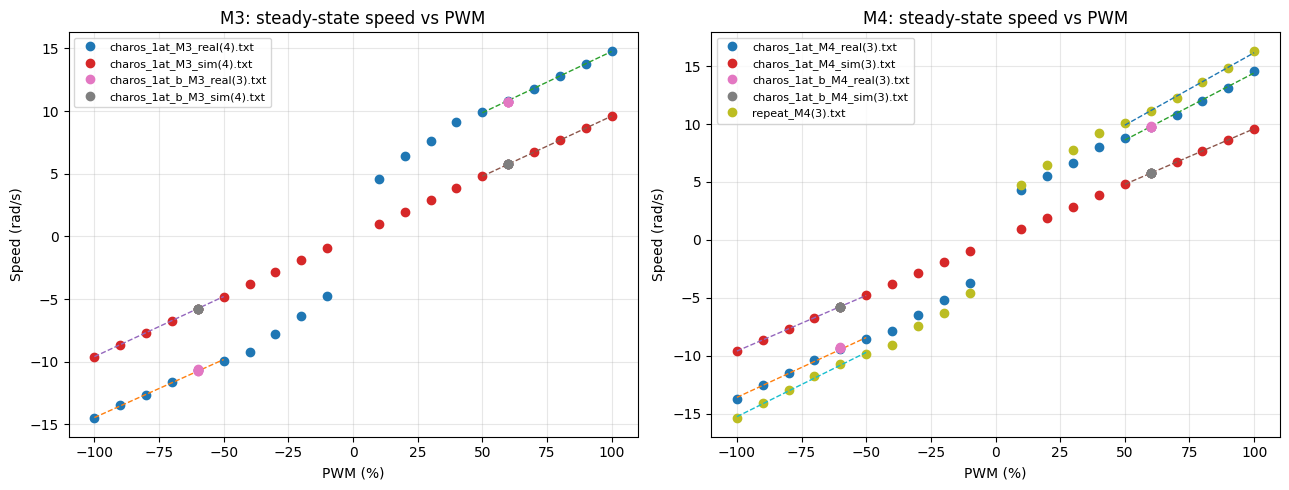

In [4]:

fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,motor in zip(axes,['M3','M4']):
    for name,d in fits.groupby('dataset'):
        if motor not in name: continue
        ax.plot(d.pwm,d.speed,'o',label=name)
        for sign in [-1,1]:
            q=d[(np.sign(d.pwm)==sign)&(abs(d.pwm)>=50)]
            if len(q)>=2 and q.pwm.nunique()>=2:
                slope,b=np.polyfit(q.pwm,q.speed,1)
                x=np.linspace(q.pwm.min(),q.pwm.max(),50)
                ax.plot(x,slope*x+b,'--',lw=1)
    ax.set(title=f'{motor}: steady-state speed vs PWM',xlabel='PWM (%)',ylabel='Speed (rad/s)')
    ax.grid(alpha=.3);ax.legend(fontsize=8)
plt.tight_layout();plt.show()


## 2. Response time at different PWM settings
The following scatter plots show the estimated time constant for each motor and recording. Points are kept as measured/fitted, without smoothing.

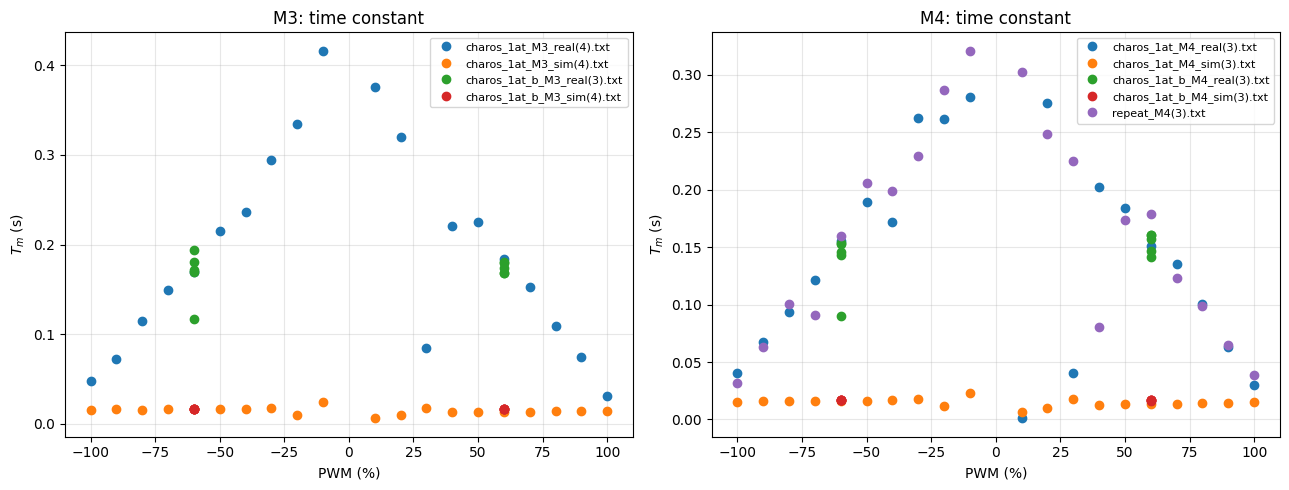

In [5]:

fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,motor in zip(axes,['M3','M4']):
    for name,d in fits.groupby('dataset'):
        if motor in name: ax.plot(d.pwm,d.T_m,'o',label=name)
    ax.set(title=f'{motor}: time constant',xlabel='PWM (%)',ylabel='$T_m$ (s)')
    ax.grid(alpha=.3);ax.legend(fontsize=8)
plt.tight_layout();plt.show()


## 3. Measured encoder angle and model prediction
For each recording, a representative PWM step is shown with its first-order model prediction. Solid lines represent recorded angles; dashed lines represent the fitted model.

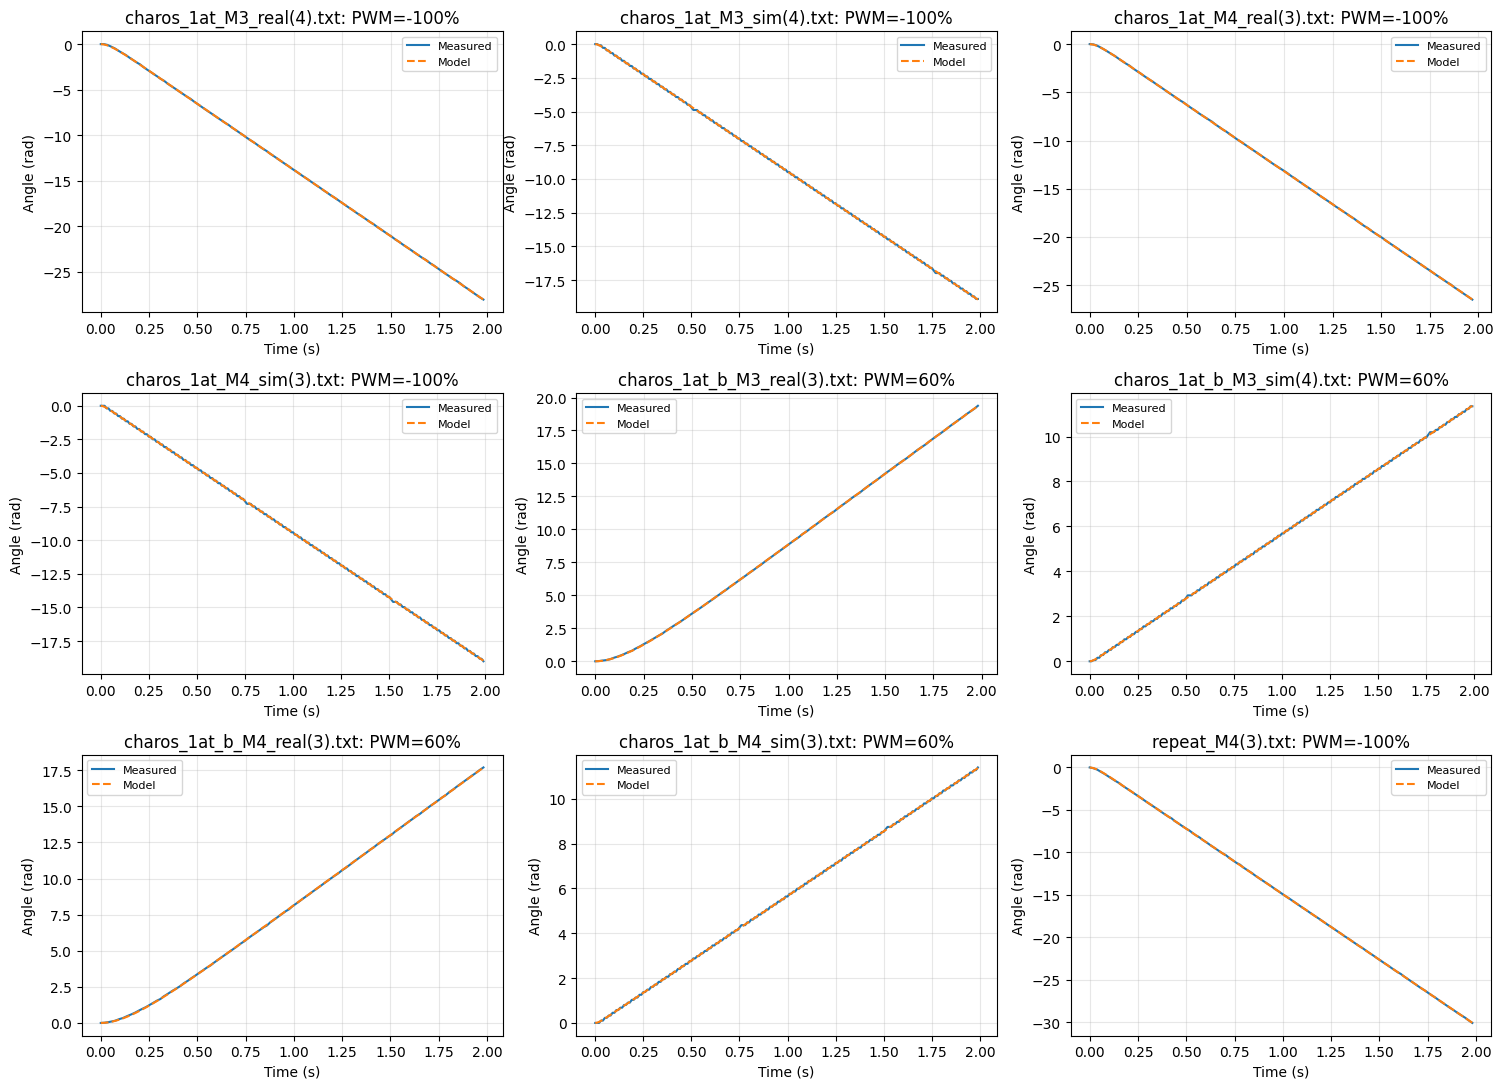

In [6]:

names=list(runs)
fig,axes=plt.subplots(3,3,figsize=(15,11))
for ax,name in zip(axes.flat,names):
    d=fits[fits.dataset==name]
    if d.empty: ax.set_title(name+' (no fitted step)');continue
    row=d.iloc[np.argmax(abs(d.pwm.to_numpy()))]
    s=row['step']
    ax.plot(s['time'],s['angle'],label='Measured')
    ax.plot(s['time'],model(s['time'],row.speed,row.T_m),'--',label='Model')
    ax.set(title=f'{name}: PWM={row.pwm:g}%',xlabel='Time (s)',ylabel='Angle (rad)')
    ax.grid(alpha=.3);ax.legend(fontsize=8)
for ax in axes.flat[len(names):]: ax.axis('off')
plt.tight_layout();plt.show()


## 4. Repeatability of M4 measurements
Repeated M4 recordings are compared in terms of steady-state speed and estimated response time.

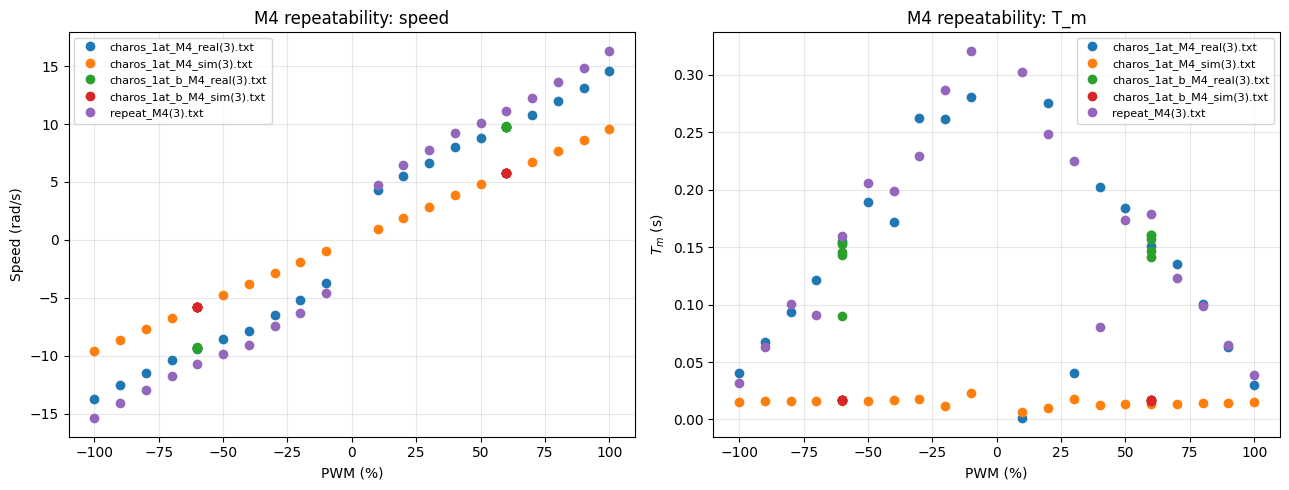

In [7]:

fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,motor,metric,ylabel in zip(axes,['M4','M4'],['speed','T_m'],['Speed (rad/s)','$T_m$ (s)']):
    for name,d in fits.groupby('dataset'):
        if motor in name: ax.plot(d.pwm,d[metric],'o',label=name)
    ax.set(title='M4 repeatability: '+metric,xlabel='PWM (%)',ylabel=ylabel)
    ax.grid(alpha=.3);ax.legend(fontsize=8)
plt.tight_layout();plt.show()


## Summary
The recorded speeds generally increase in magnitude as the PWM magnitude increases. Real and simulated motors follow similar overall trends, although their speeds and response times differ. The repeated M4 tests show that speed is more consistent across runs than the estimated time constant. The first-order model captures the general angle response of the tested motors, but the agreement varies with the operating condition.